>Начнем с простого запуска. Нам понадобятся:
* ```waggon.f```: ф-ия черного ящика
* ```waggon.surrogates```: cуррогат - модель регрессии для аппроксимации ф-ии черного ящика
* ```waggon.acquisitions```: ф-ия выбора (acquisition f-n) - стратегия выбора кандидата на оптимум на каждой итерации
* ```waggon.optim```: классы оптимизационных алгоритмов

In [1]:
from waggon import functions as f
from waggon.surrogates import GP
from waggon.acquisitions import EI
from waggon.optim import SurrogateOptimiser

Optimisation error: 2.0777:   0%|          | 0/10 [00:00<?, ?it/s]

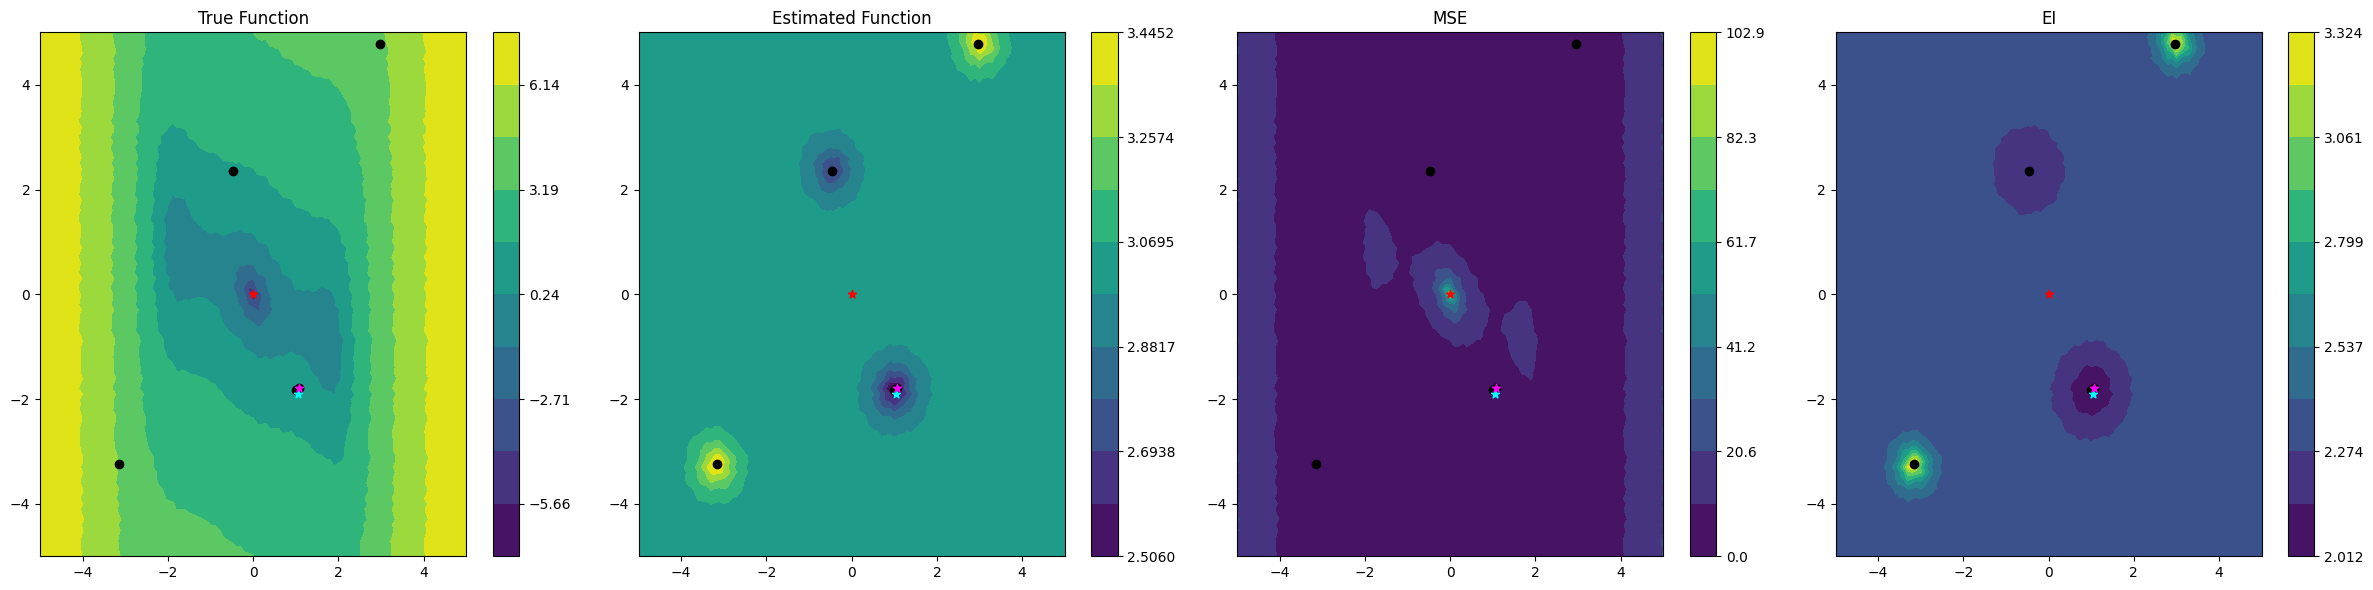

Optimisation error: 2.0777:  10%|█         | 1/10 [00:01<00:14,  1.61s/it]

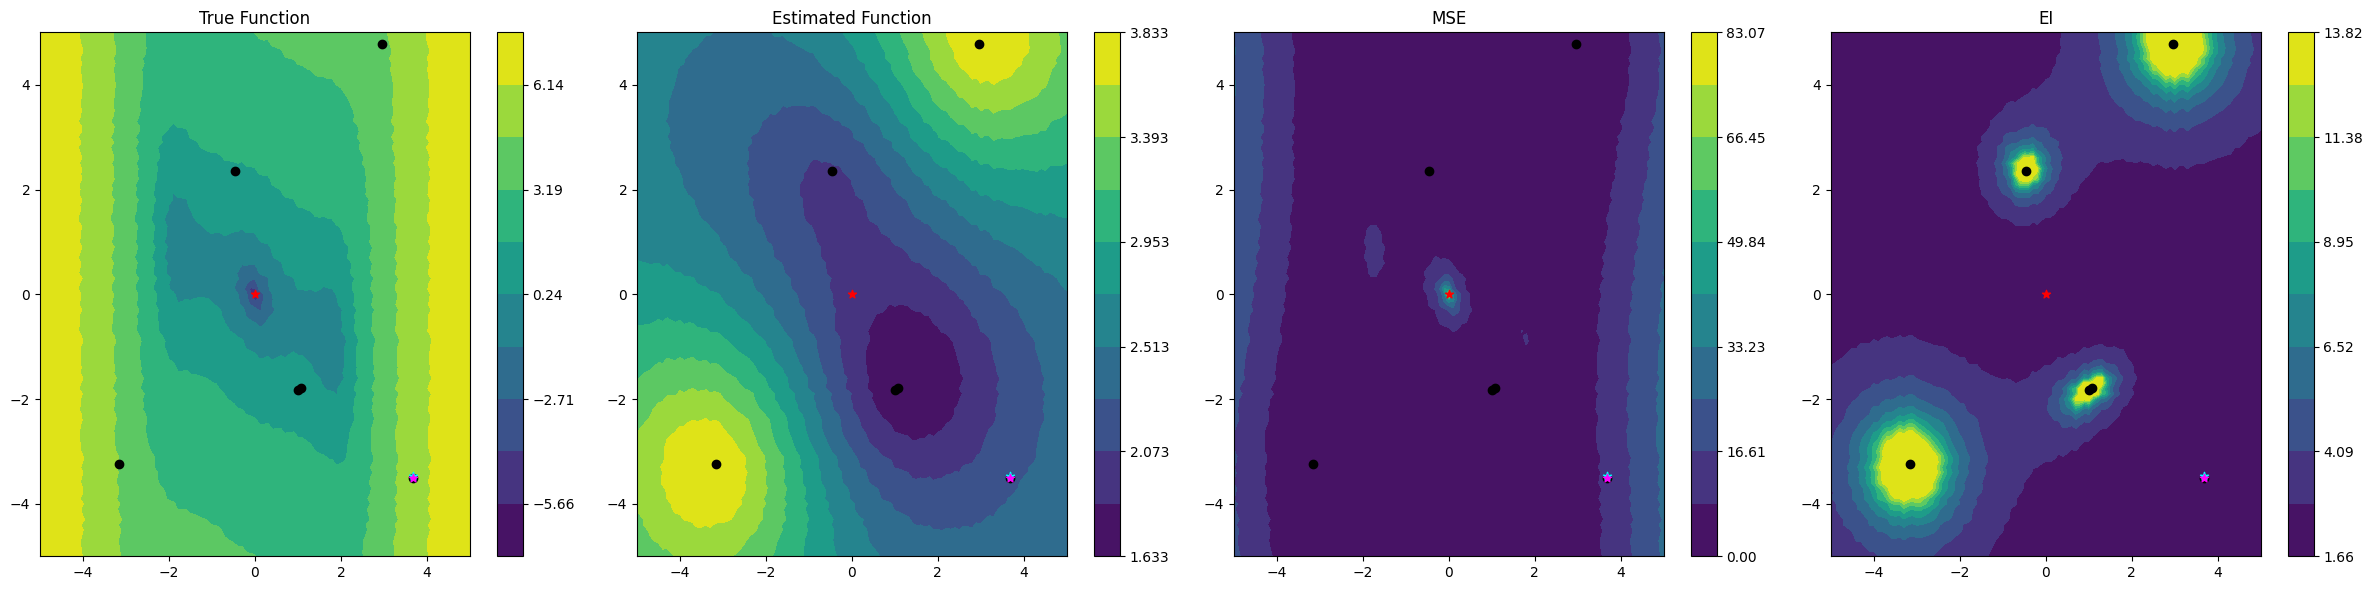

Optimisation error: 2.0777:  20%|██        | 2/10 [00:03<00:12,  1.56s/it]

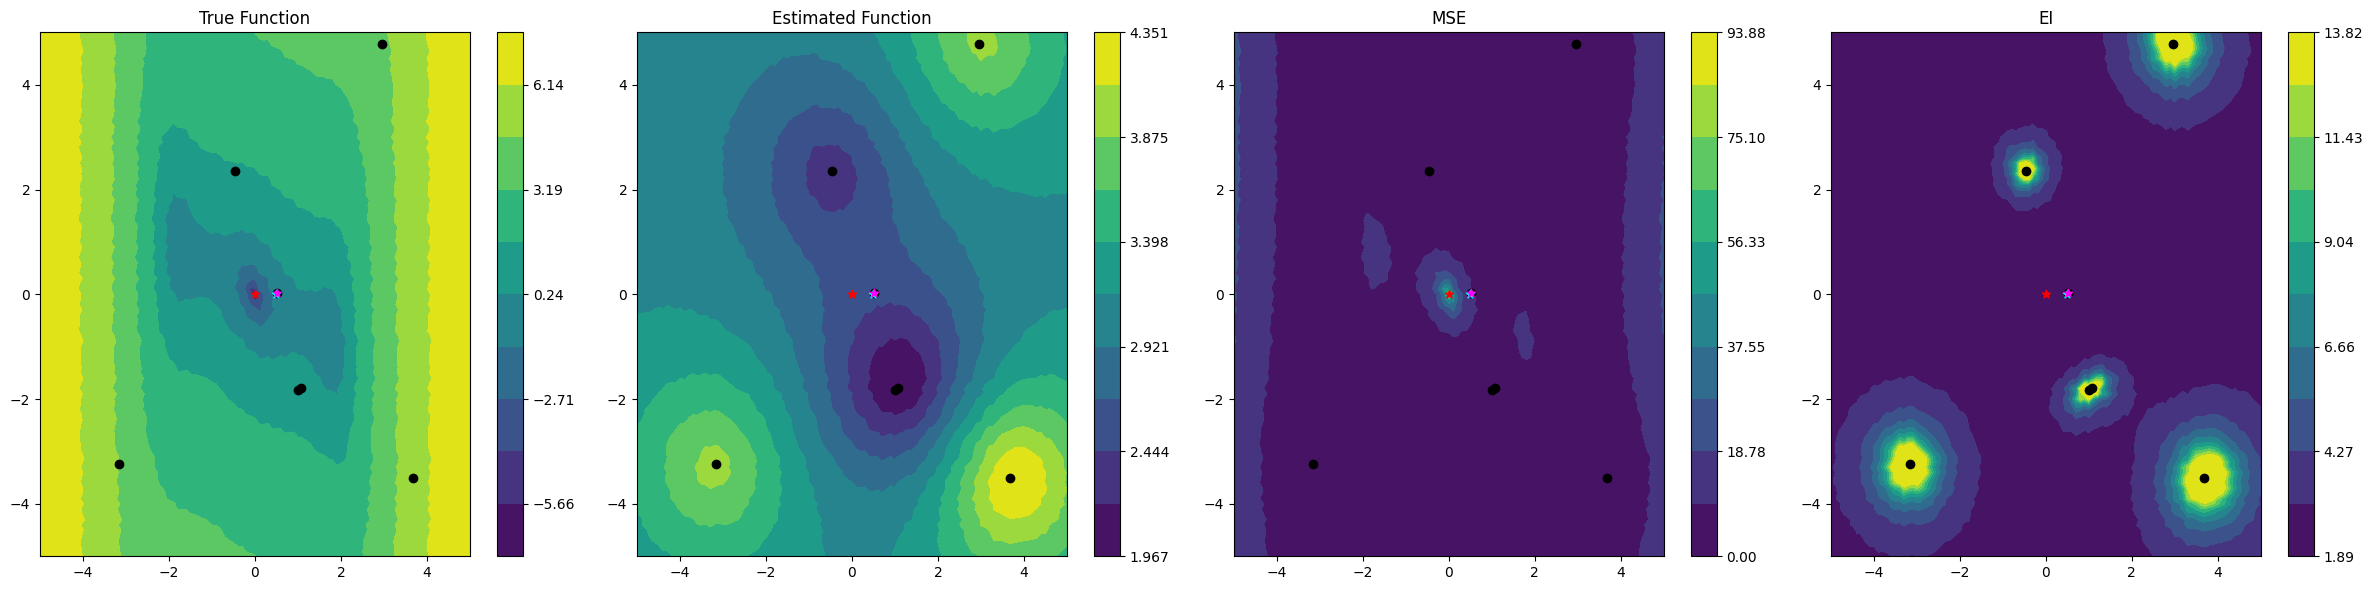

Optimisation error: 0.5085:  30%|███       | 3/10 [00:04<00:11,  1.58s/it]

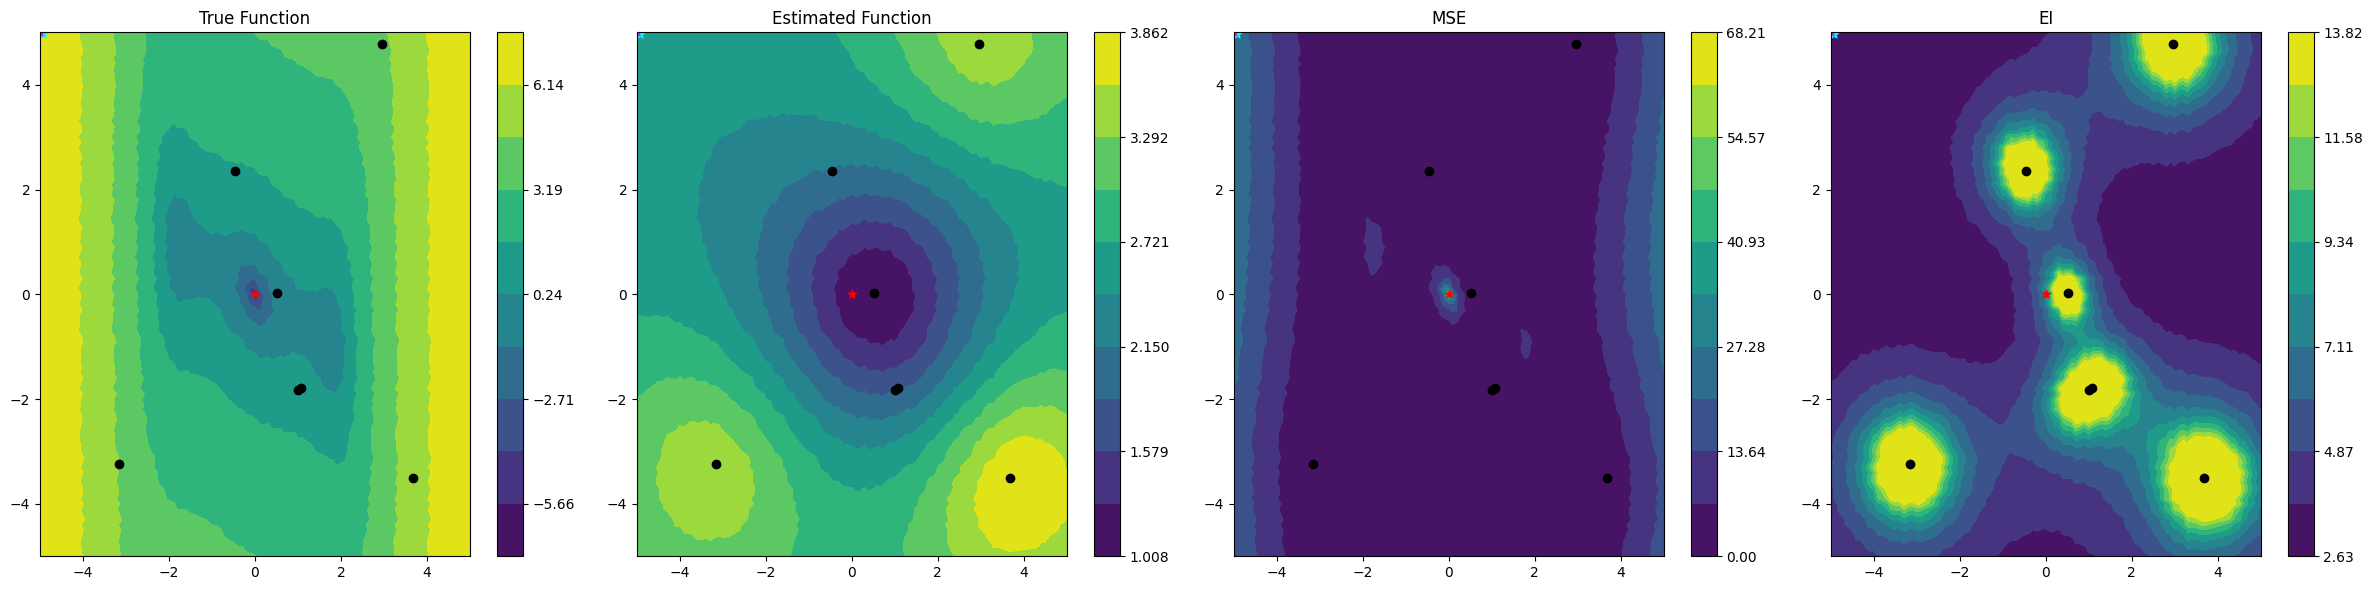

Optimisation error: 0.5085:  40%|████      | 4/10 [00:06<00:09,  1.56s/it]

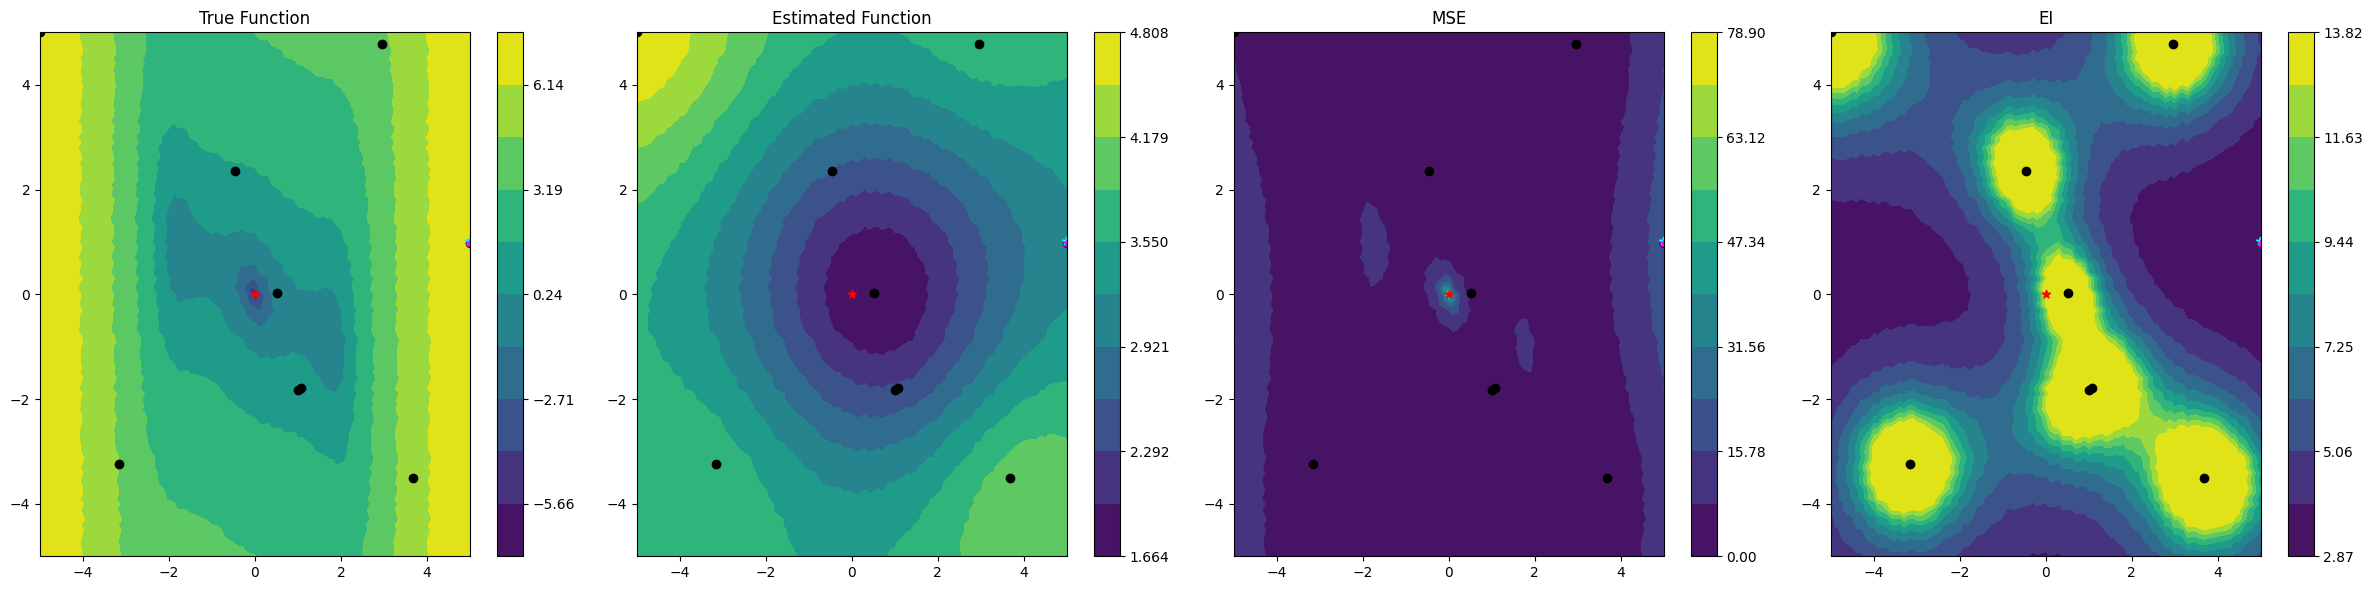

Optimisation error: 0.5085:  50%|█████     | 5/10 [00:07<00:07,  1.55s/it]

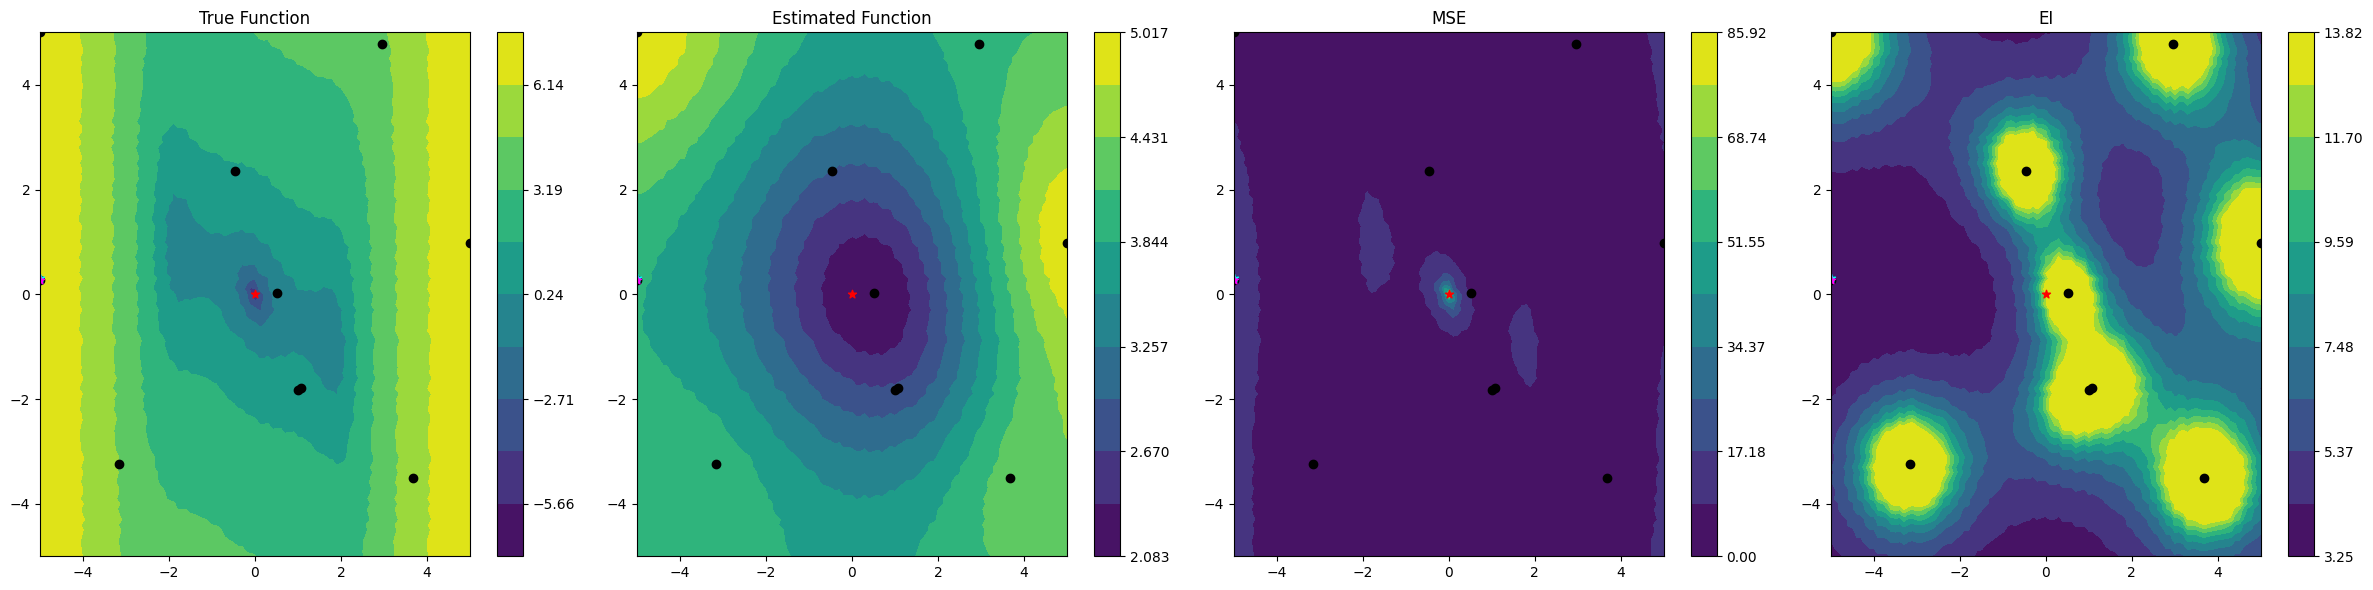

Optimisation error: 0.5085:  60%|██████    | 6/10 [00:09<00:06,  1.58s/it]

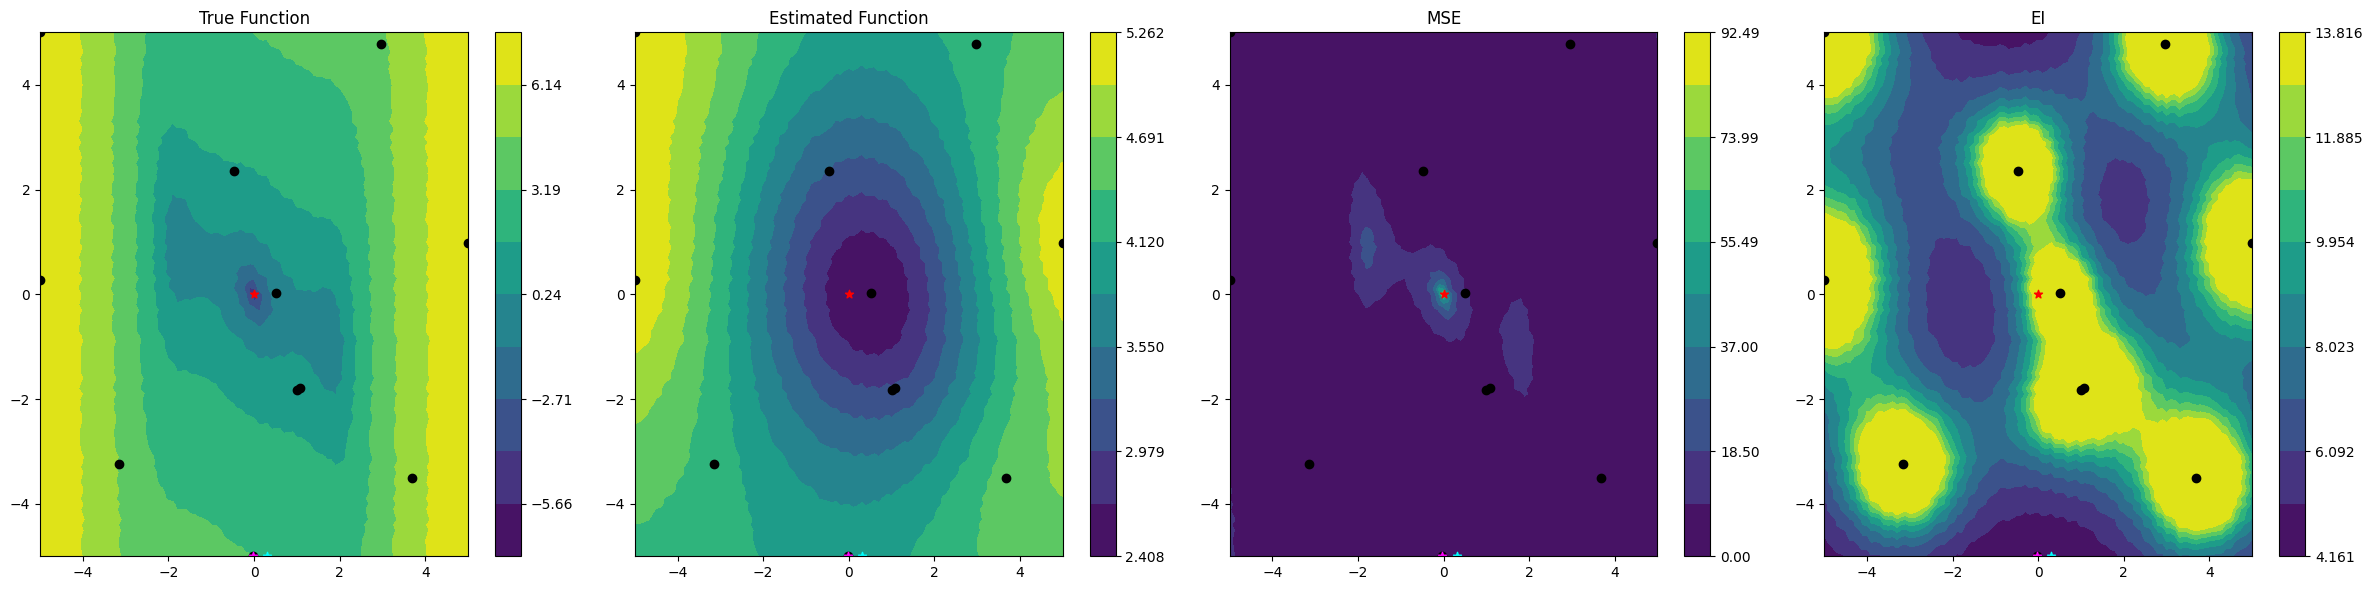

Optimisation error: 0.5085:  70%|███████   | 7/10 [00:11<00:04,  1.60s/it]

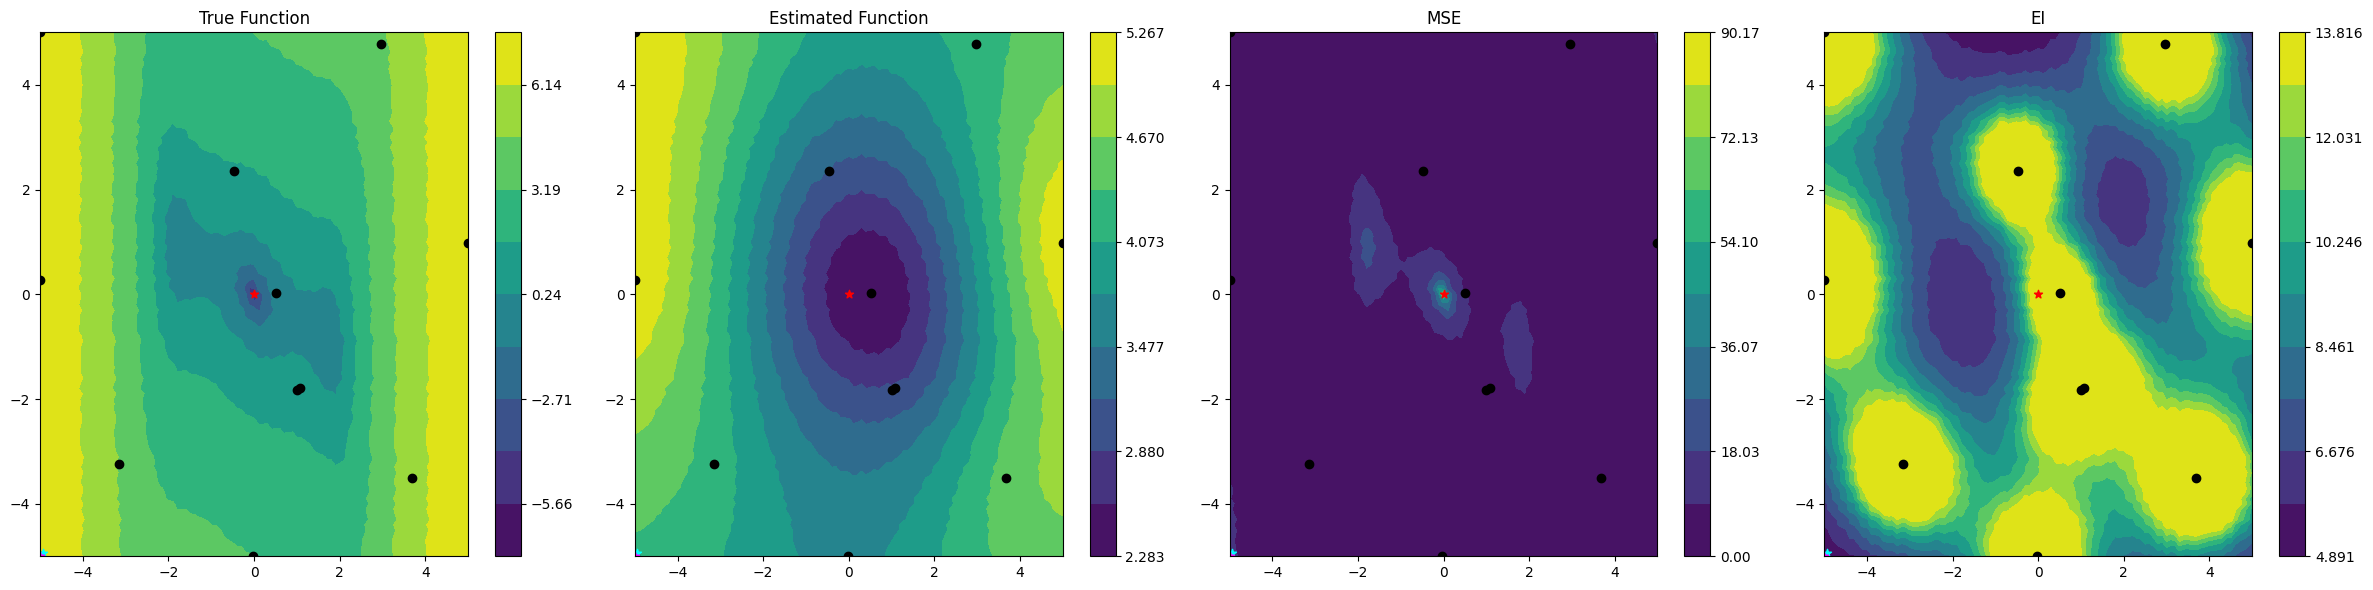

Optimisation error: 0.5085:  80%|████████  | 8/10 [00:12<00:03,  1.65s/it]

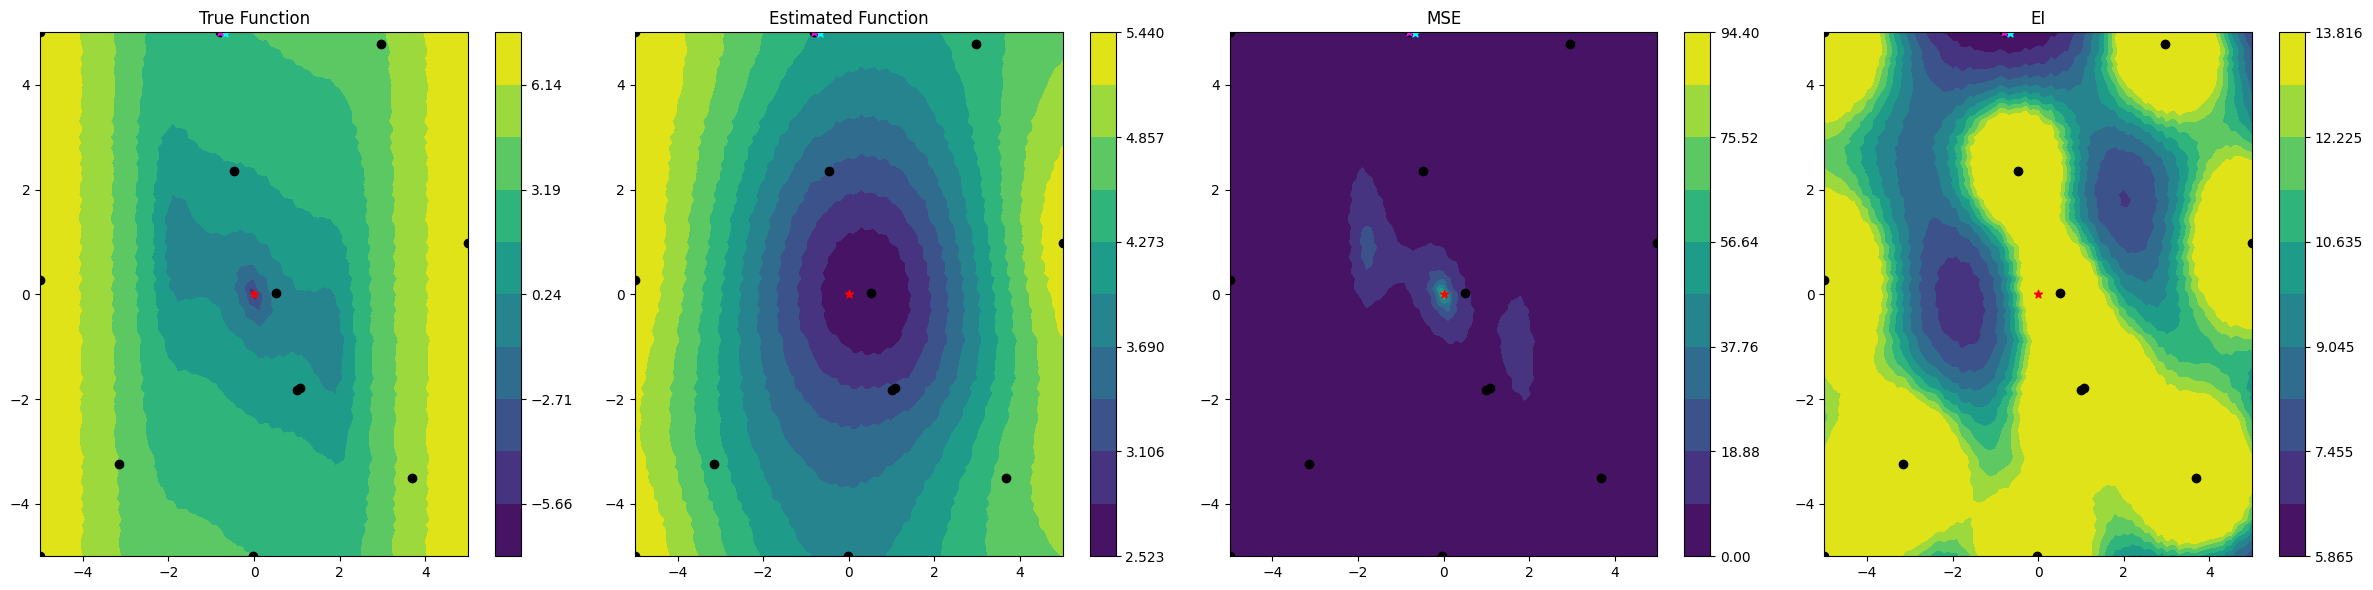

Optimisation error: 0.5085:  90%|█████████ | 9/10 [00:14<00:01,  1.66s/it]

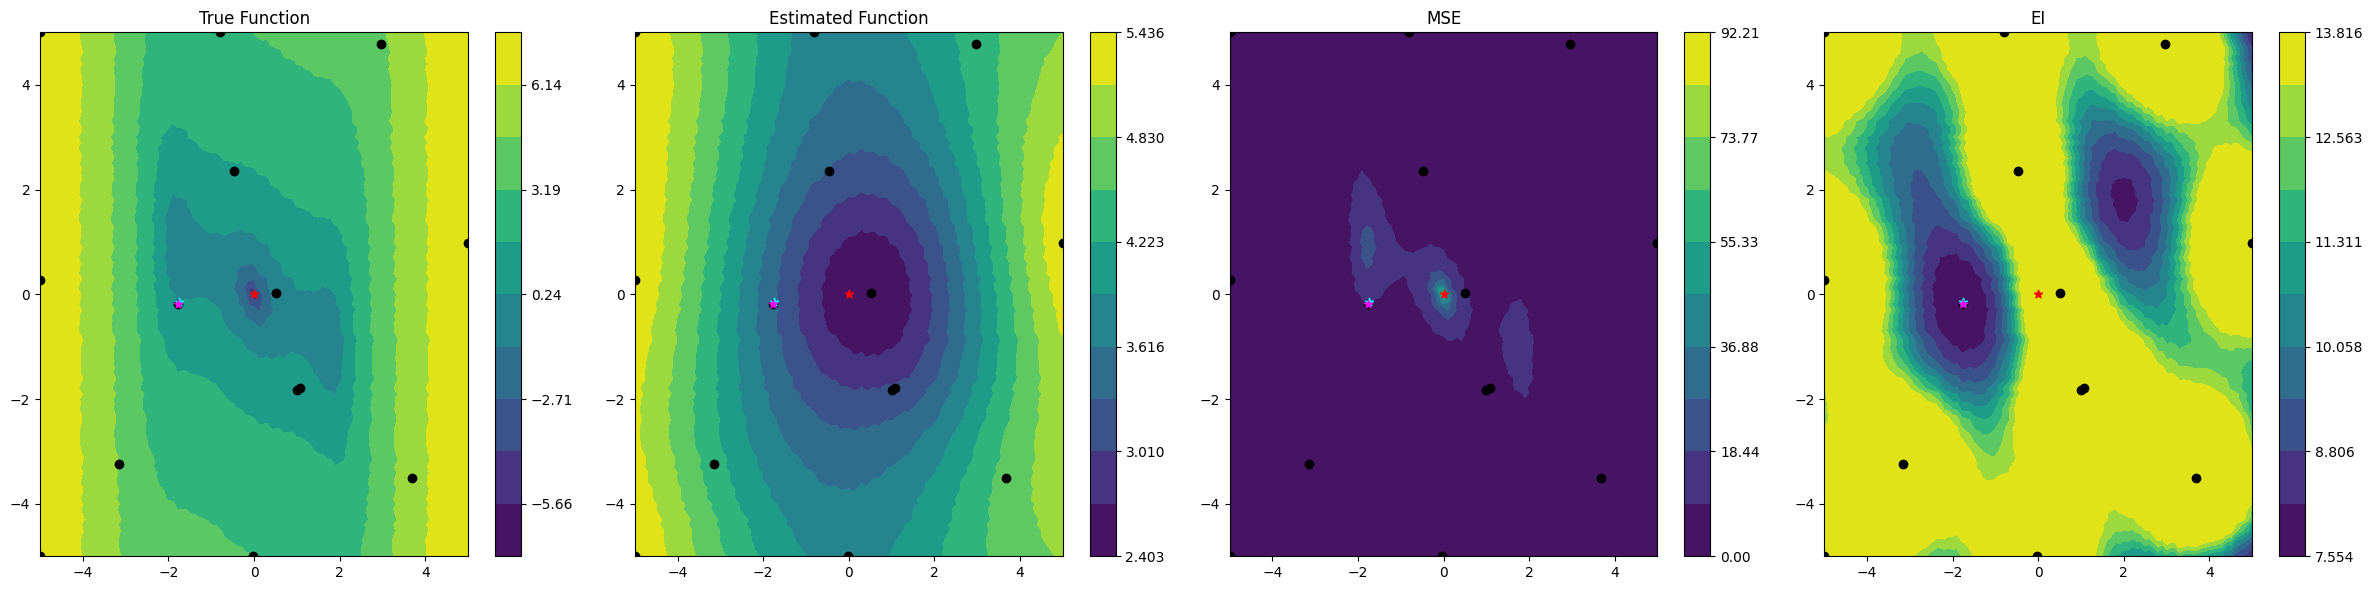

Optimisation error: 0.5085: 100%|██████████| 10/10 [00:16<00:00,  1.63s/it]

Experiment failed


In [2]:
opt = SurrogateOptimiser( # возьмем алгоритм суррогатной оптимизации а.к.а. Байесовская оптимизация и не только
            func=f.three_hump_camel(), # передадим ему ф-ю черного ящика
            surr=GP(), # суррогатную модель
            acqf=EI(), # ф-ю выбору
            seed=2, # сид фиксирует позицию изначальных 2 * d точек - нужно для воспроизводимости
            max_iter=10, # максимальное кол-во итерации
            plot_results=True # рисует ф-ию, аппроскимацию, ско аппрексимации, ф-ю выбора; черные точки - известные тру значения,
            # ЗВЕЗДЫ: красная - глобальный оптимум, голубая - оценка оптимума ф-ии выбора, розовая - выбранная точка
)
_ = opt.optimise()

>Модульная структуры позволяет просто менять компоненты алгоритма оптимизации. Попробуем глубинный гауссовский процесс вместо обычного

In [2]:
from waggon.surrogates import DGP

Optimisation error: 2.0777:   0%|          | 0/10 [00:00<?, ?it/s]

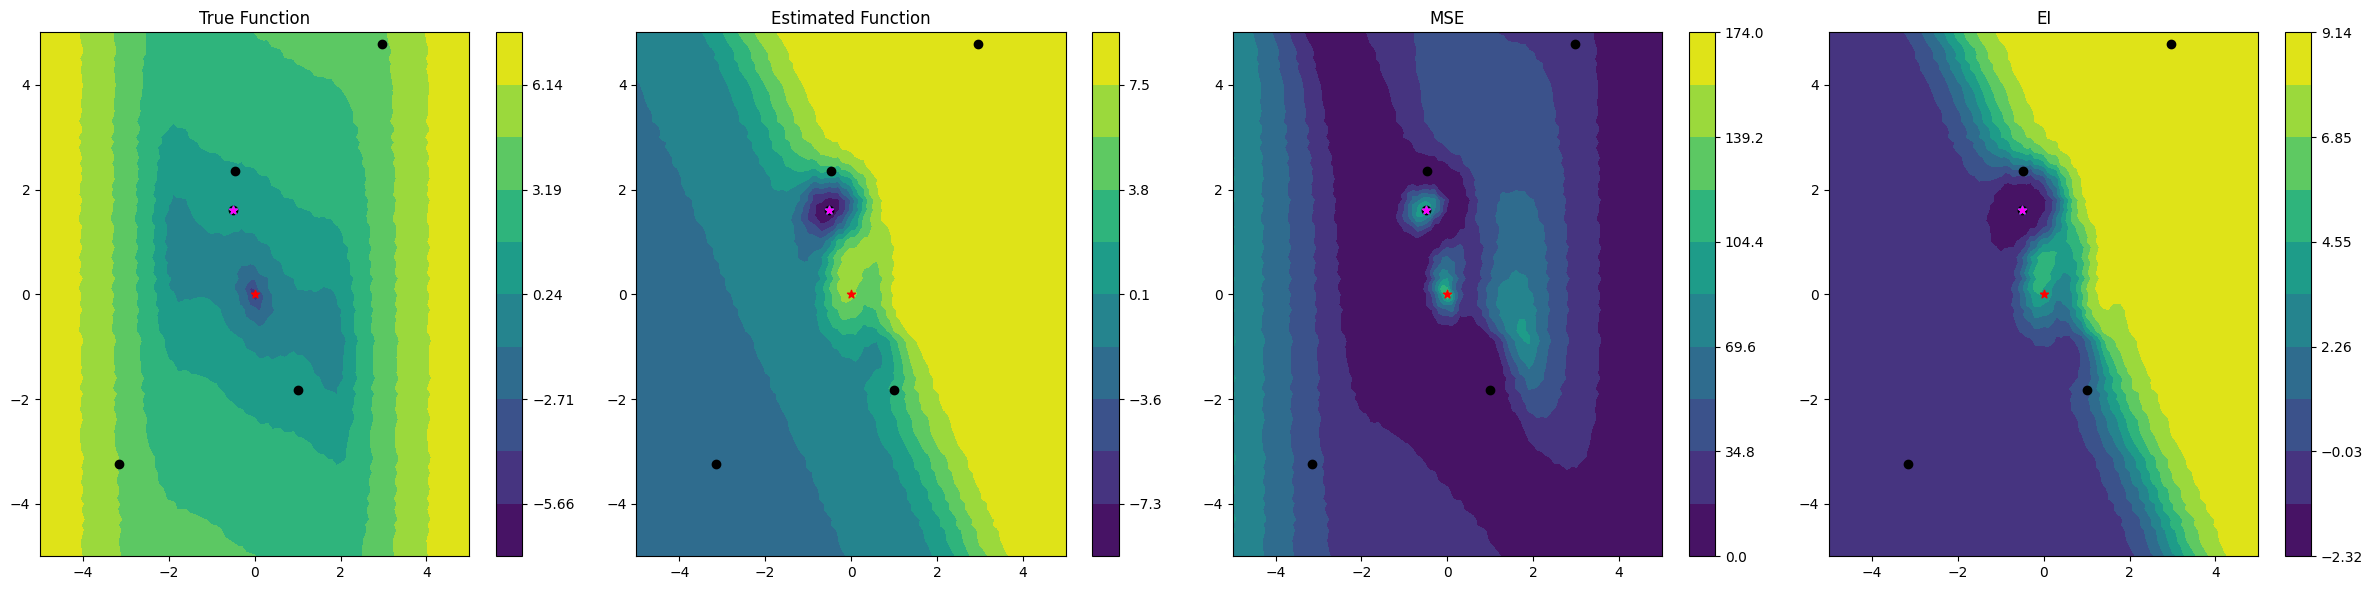

Optimisation error: 1.6920:  10%|█         | 1/10 [00:08<01:17,  8.63s/it]

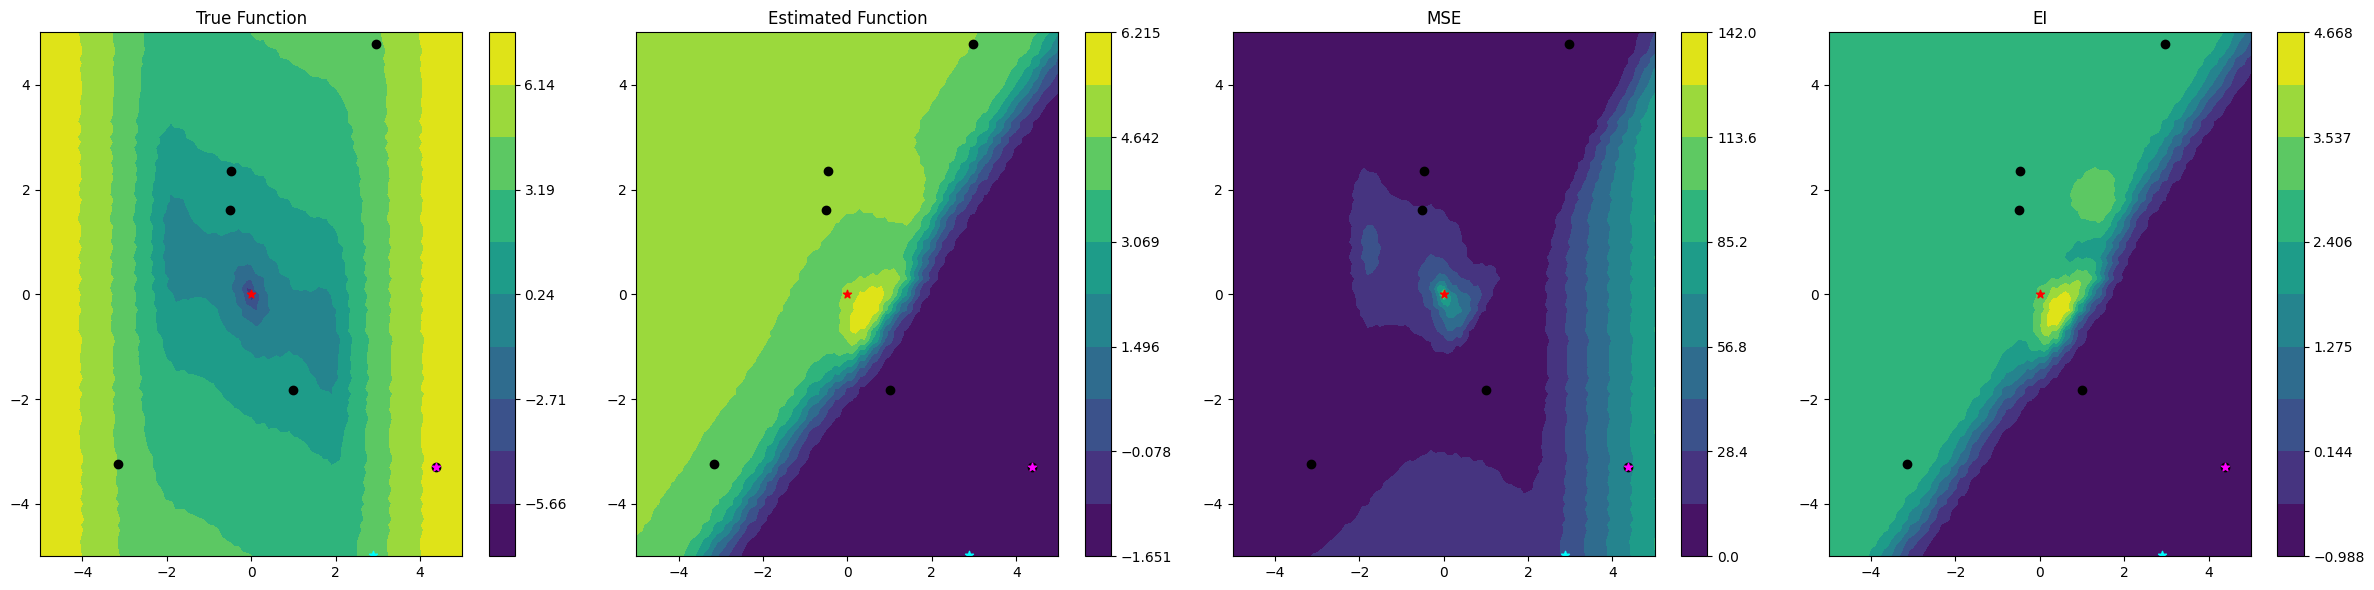

Optimisation error: 1.6920:  20%|██        | 2/10 [00:13<00:51,  6.48s/it]

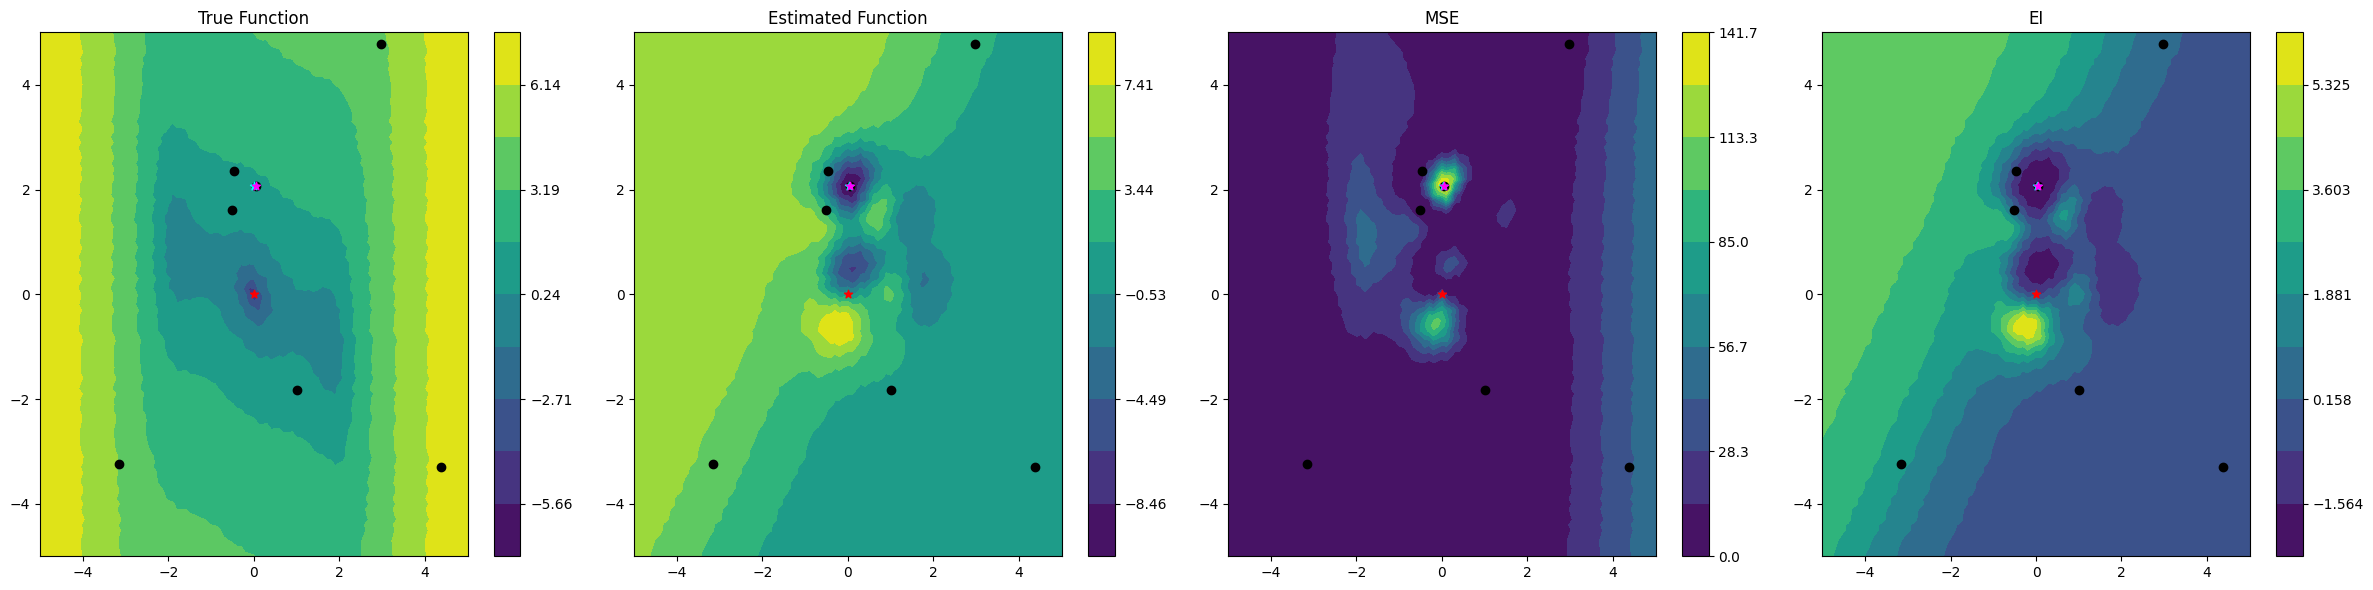

Optimisation error: 1.6920:  30%|███       | 3/10 [00:26<01:05,  9.30s/it]

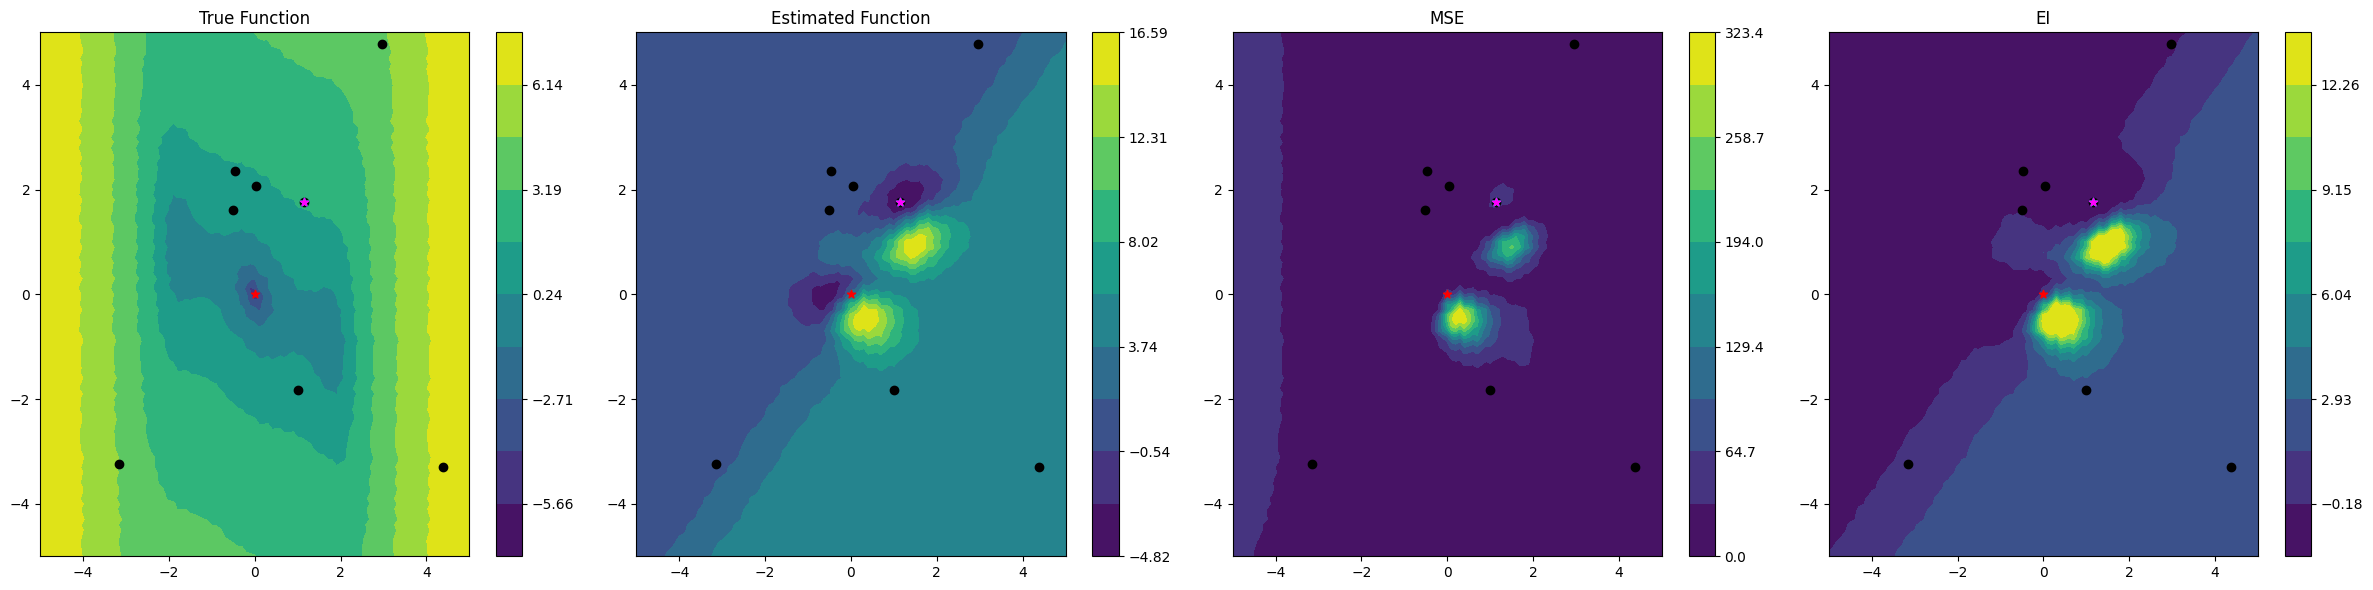

Optimisation error: 1.6920:  40%|████      | 4/10 [00:36<00:59,  9.87s/it]

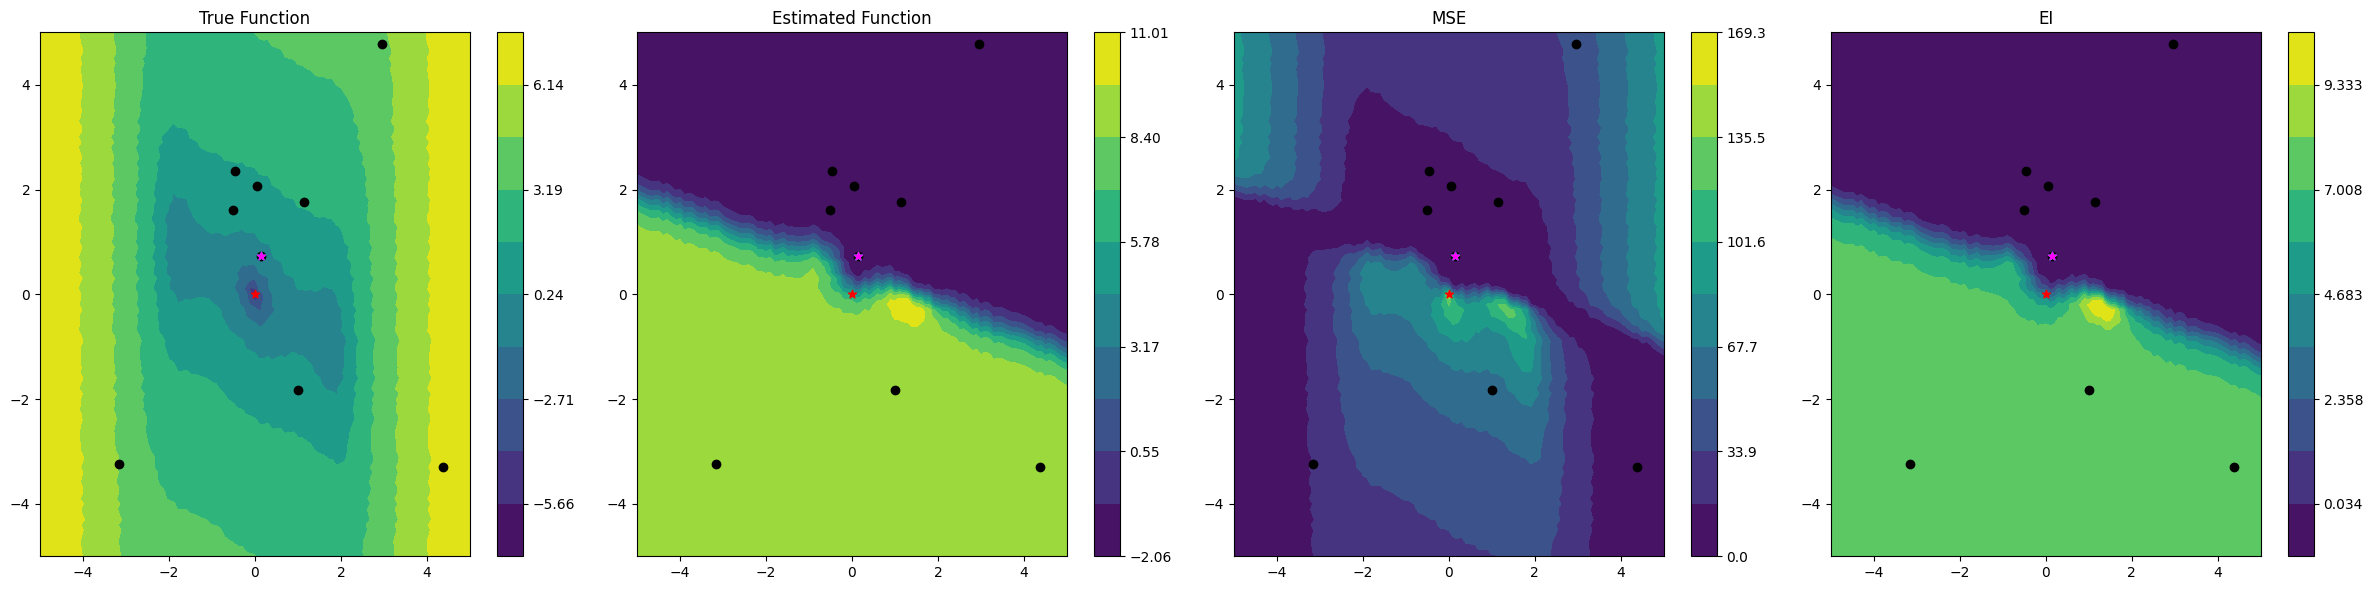

Optimisation error: 0.7489:  50%|█████     | 5/10 [00:43<00:43,  8.76s/it]

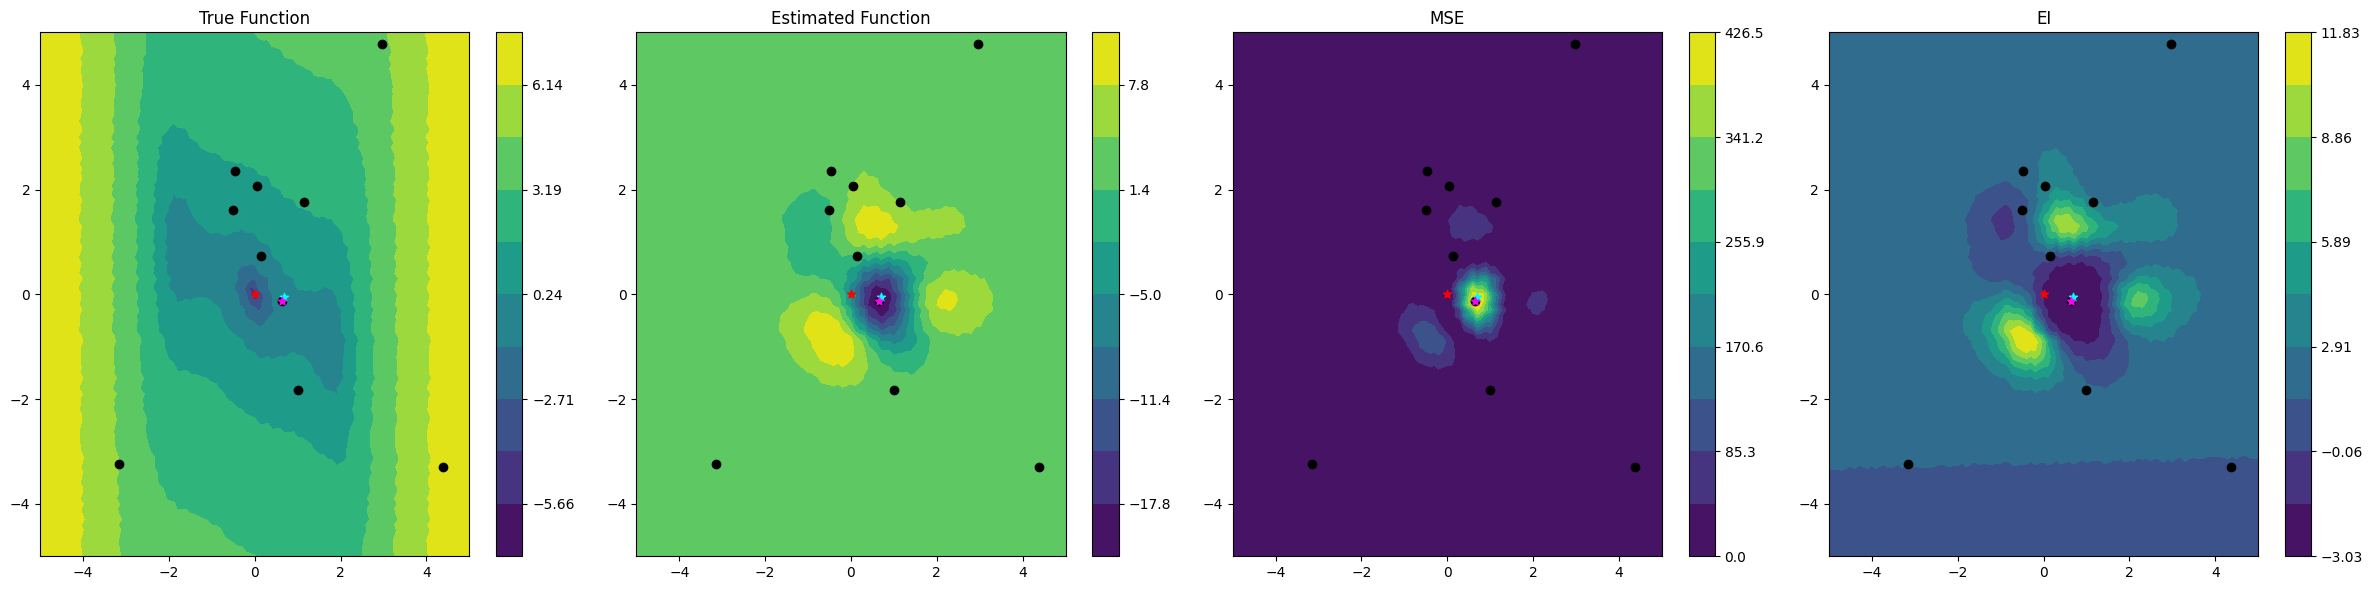

Optimisation error: 0.6587:  60%|██████    | 6/10 [00:57<00:41, 10.28s/it]

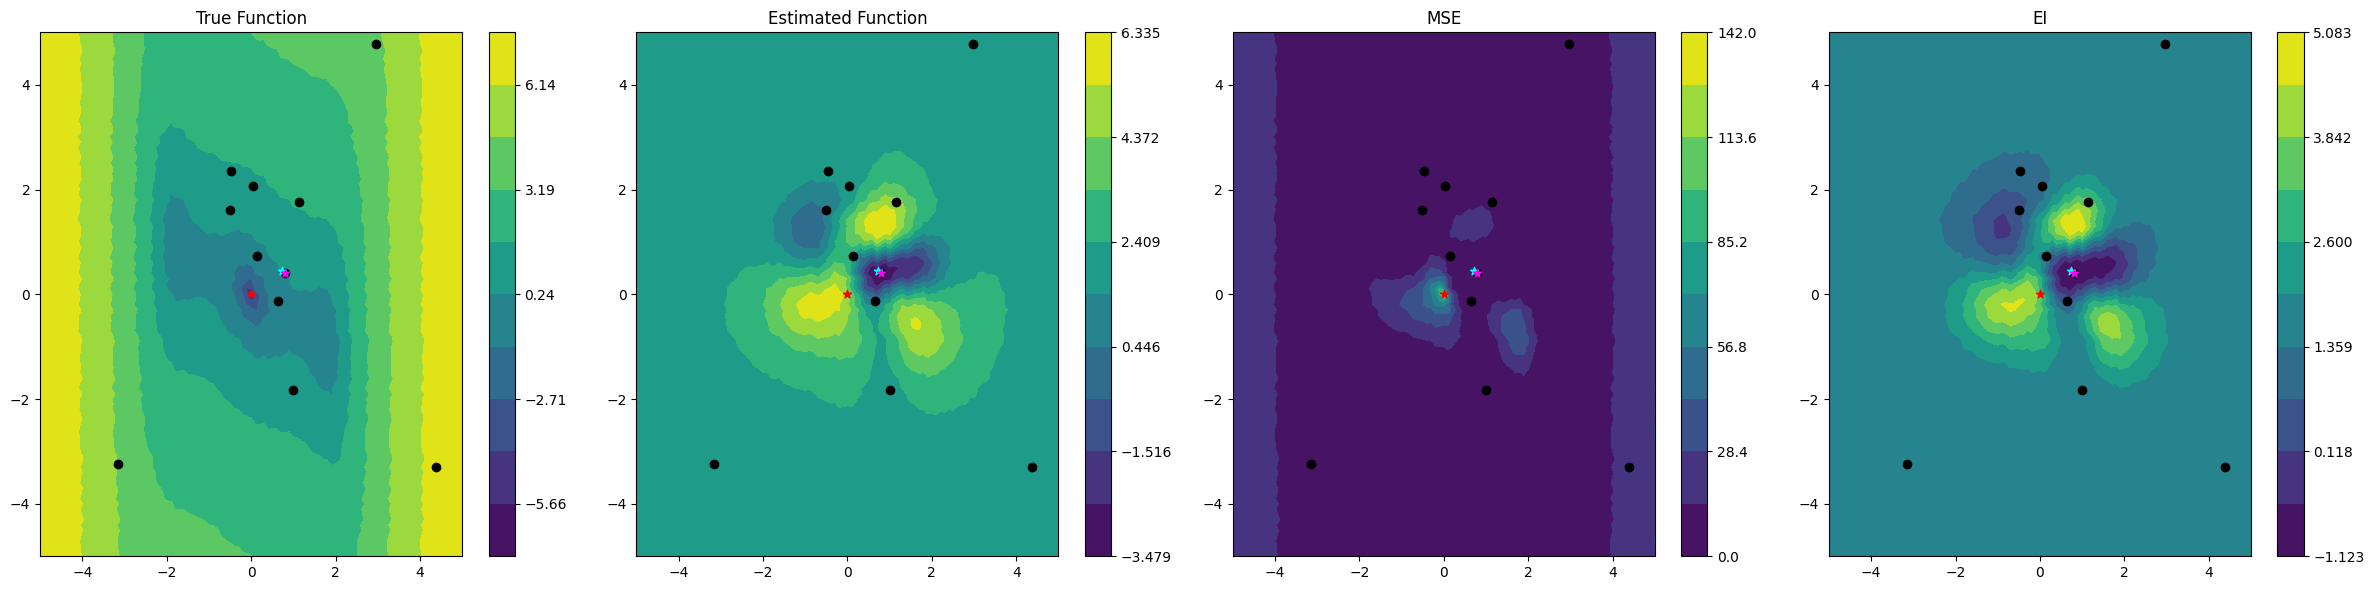

Optimisation error: 0.6587:  70%|███████   | 7/10 [01:05<00:28,  9.59s/it]

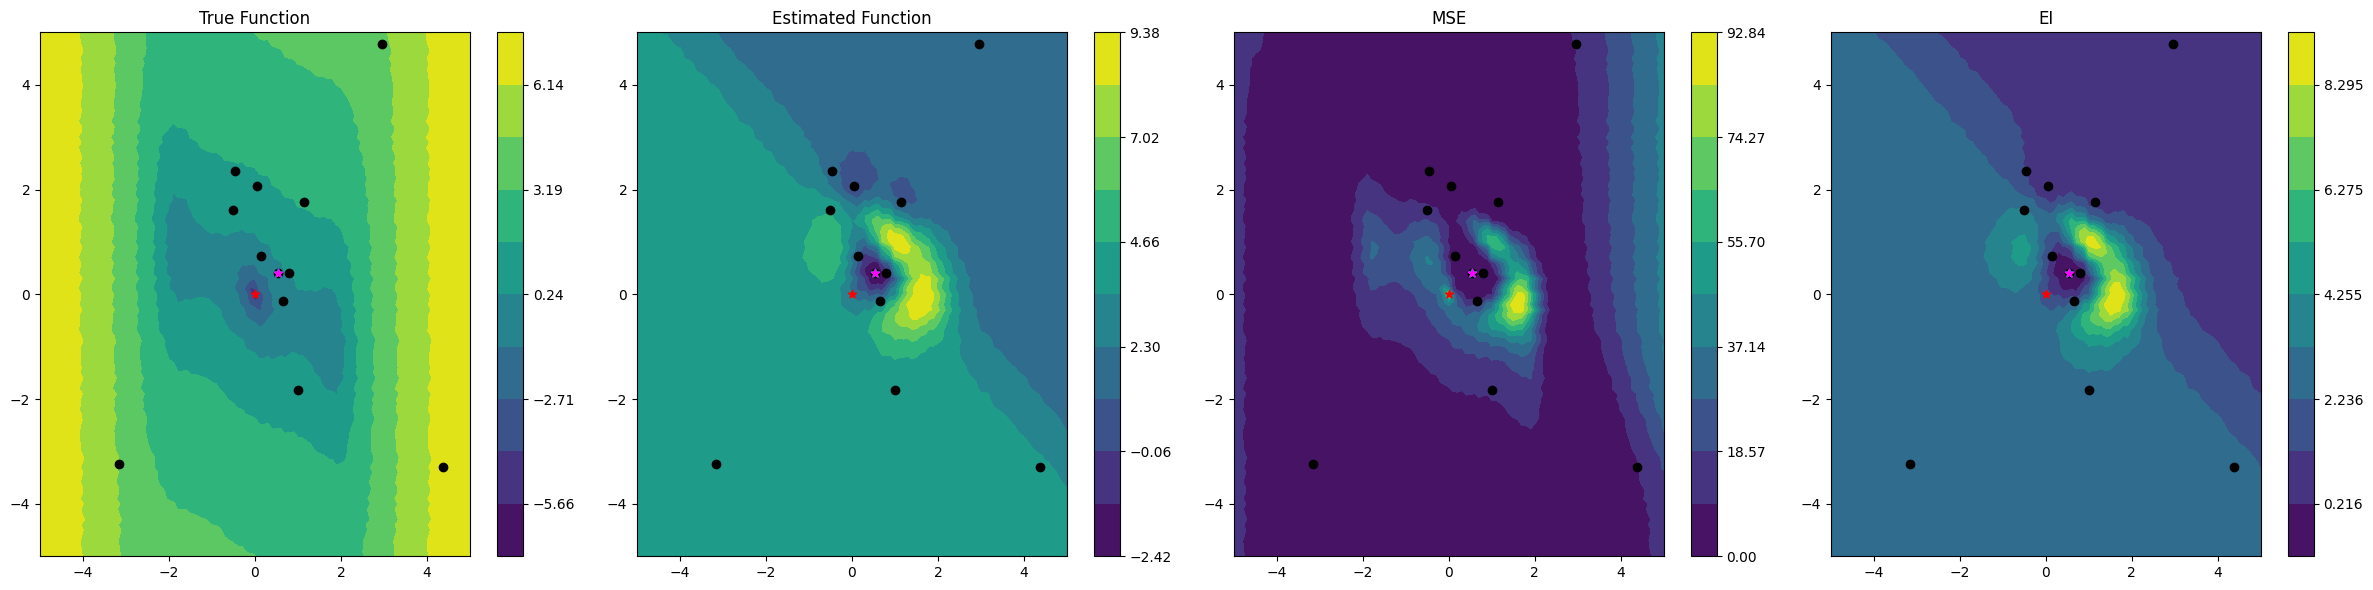

Optimisation error: 0.6587:  80%|████████  | 8/10 [01:15<00:19,  9.77s/it]

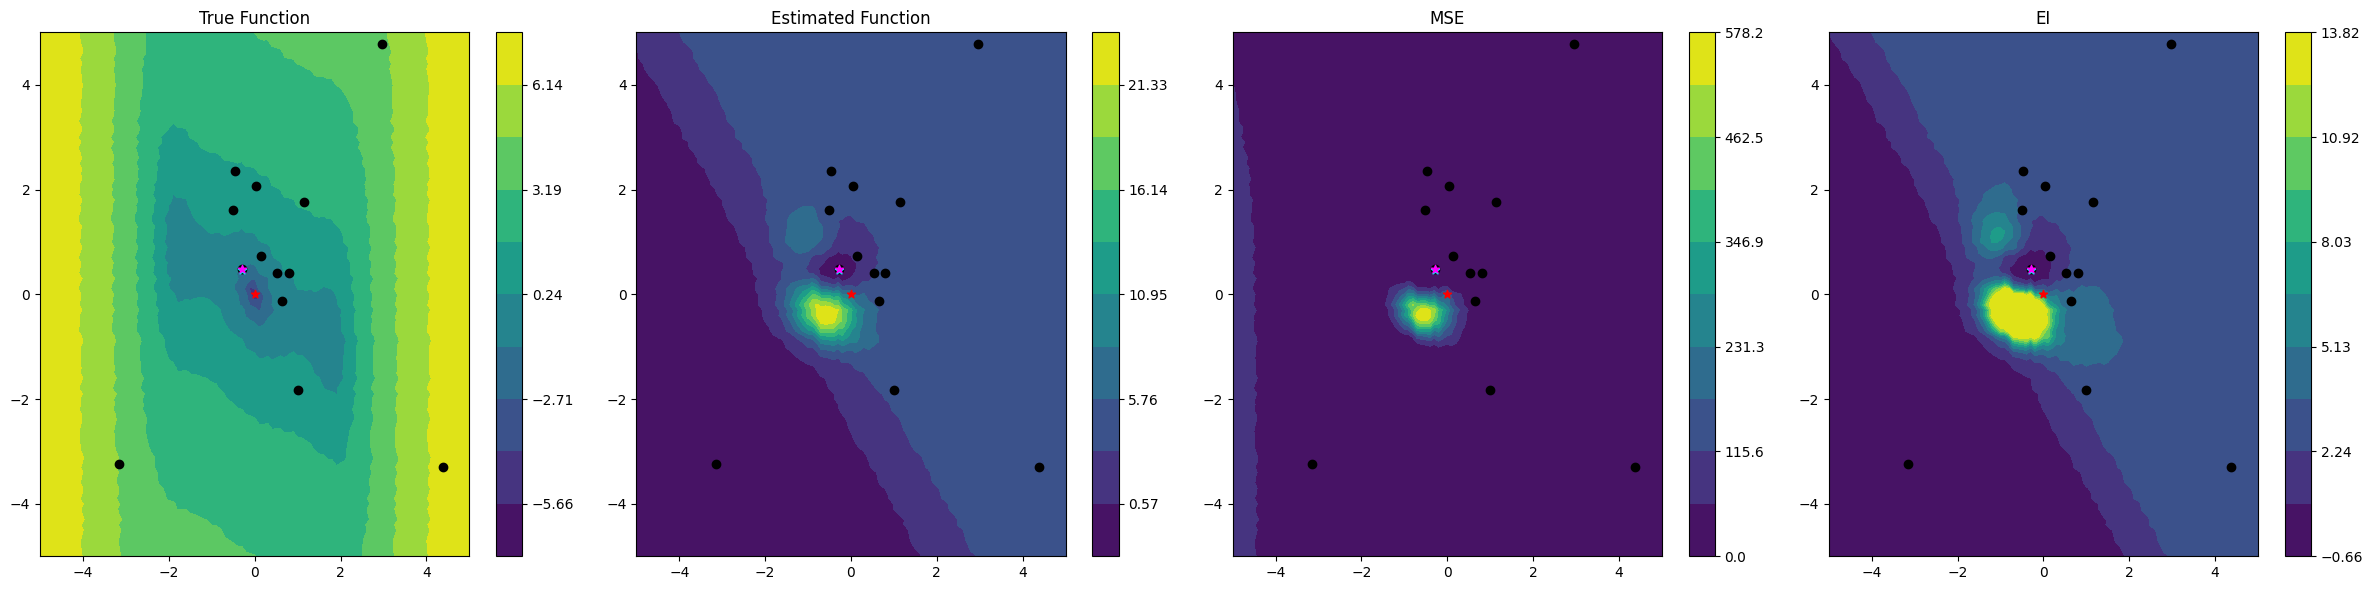

Optimisation error: 0.5650:  90%|█████████ | 9/10 [01:22<00:08,  8.81s/it]

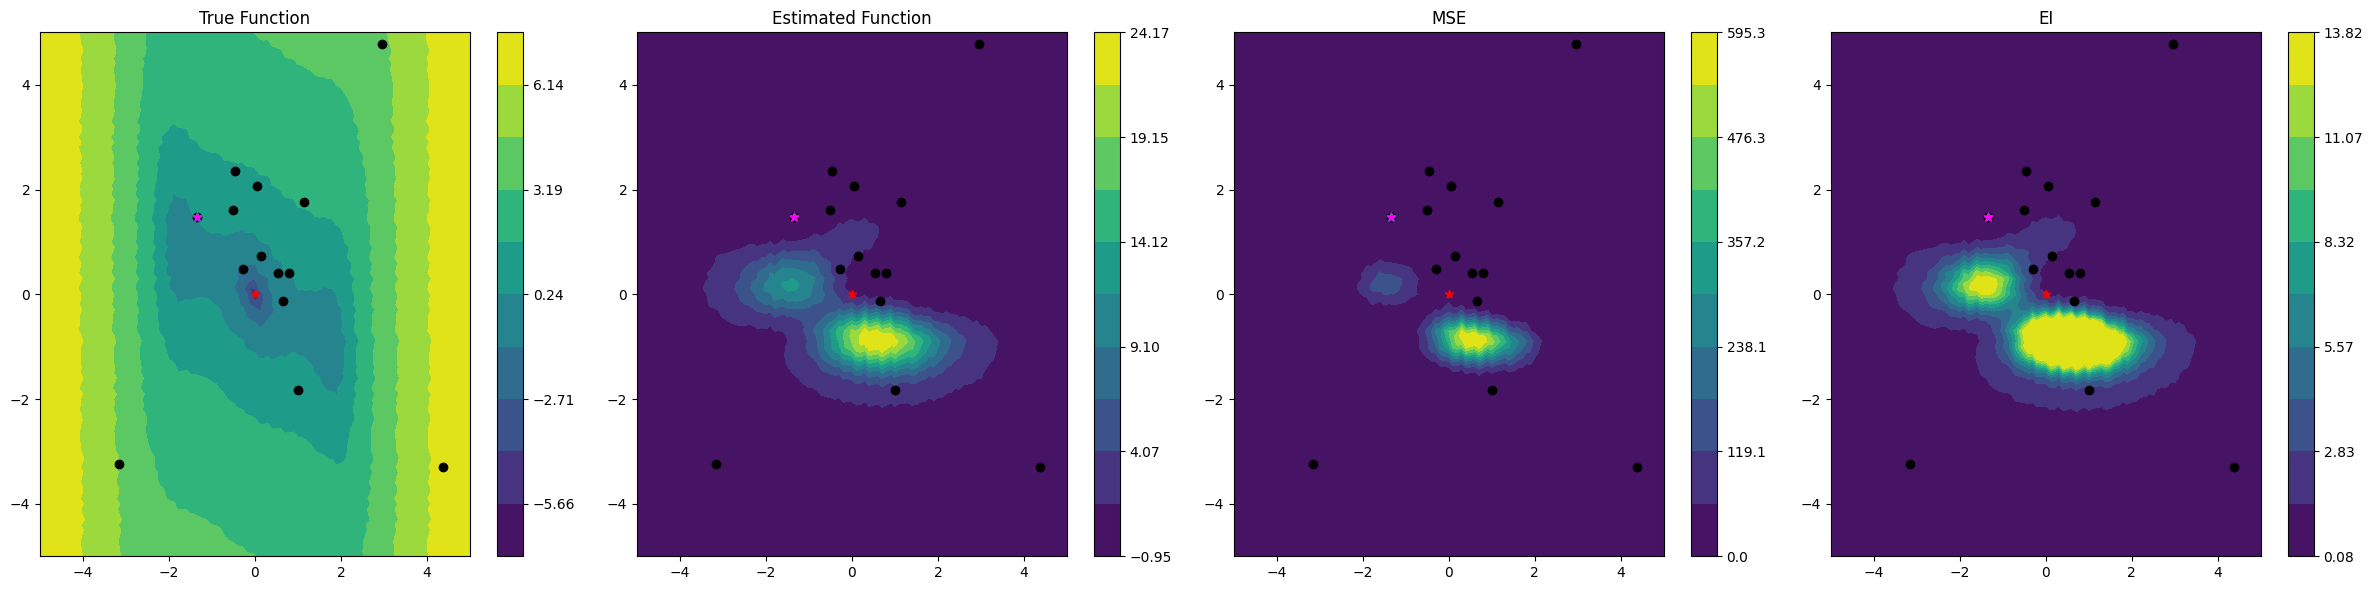

Optimisation error: 0.5650: 100%|██████████| 10/10 [01:31<00:00,  9.11s/it]

Experiment failed


In [6]:
opt = SurrogateOptimiser(
            func=f.three_hump_camel(),
            surr=DGP(n_epochs=10),
            acqf=EI(),
            seed=2,
            max_iter=10,
            plot_results=True,
            verbose=2
)
_ = opt.optimise()

>Как мы видим, за 10 эпох суррогат недообучается, из-за чего аппроксимация на первых итерациях не самая лучшая.

>Теперь попробуем другую ф-ю выбора. Например, (Lower) Confidence Bound

In [3]:
from waggon.acquisitions import CB

Optimisation error: 2.0777:   0%|          | 0/10 [00:00<?, ?it/s]

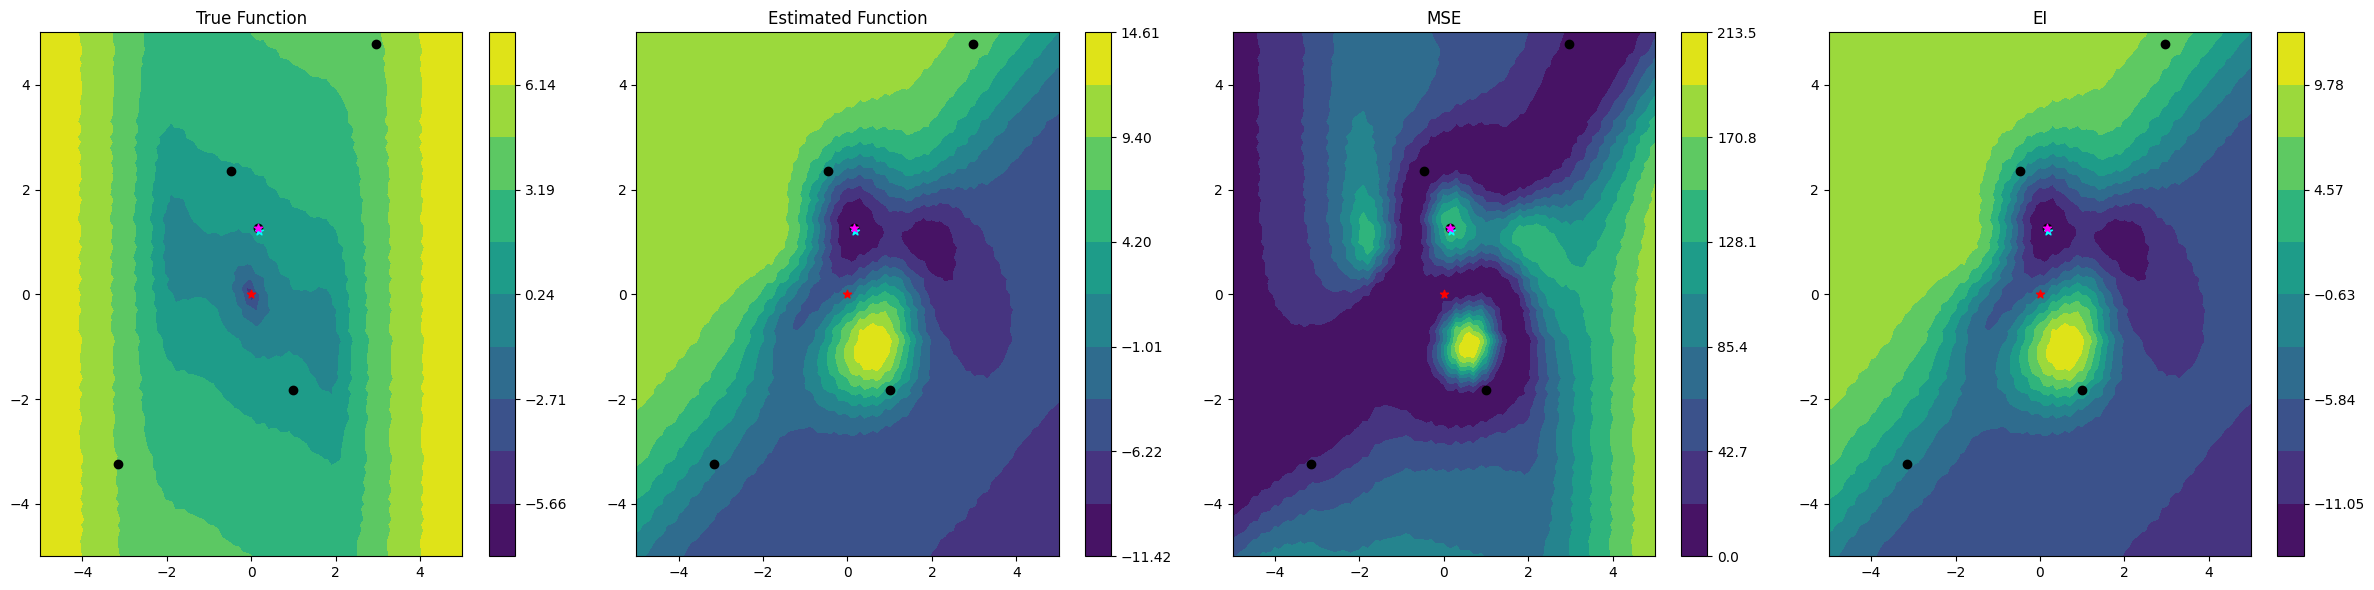

Optimisation error: 1.2826:  10%|█         | 1/10 [00:08<01:19,  8.86s/it]

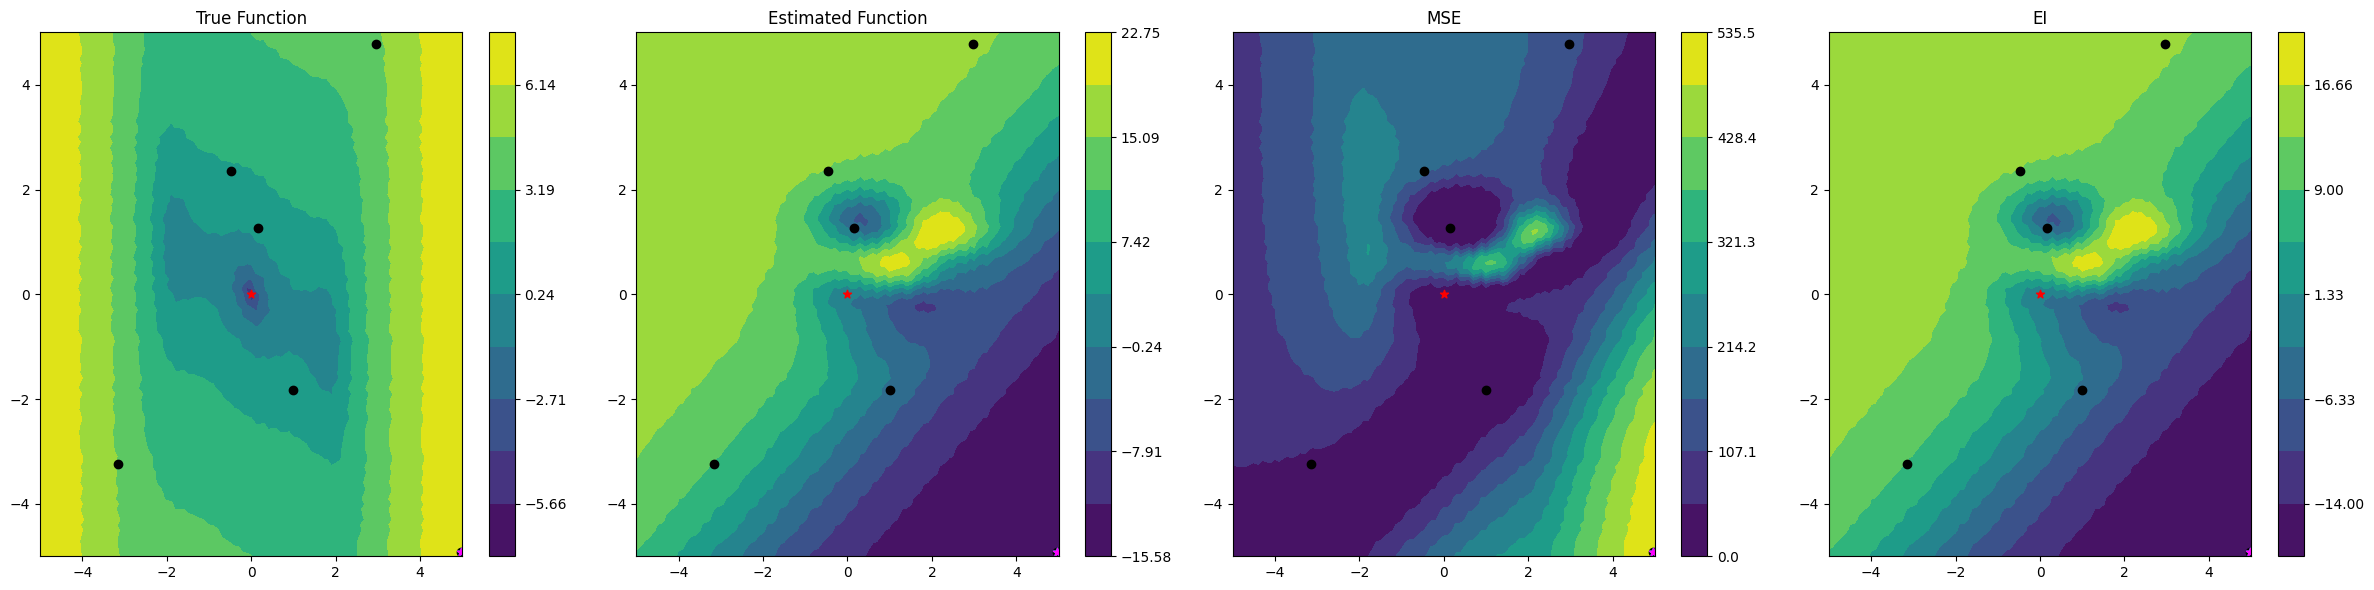

Optimisation error: 1.2826:  20%|██        | 2/10 [00:14<00:53,  6.72s/it]

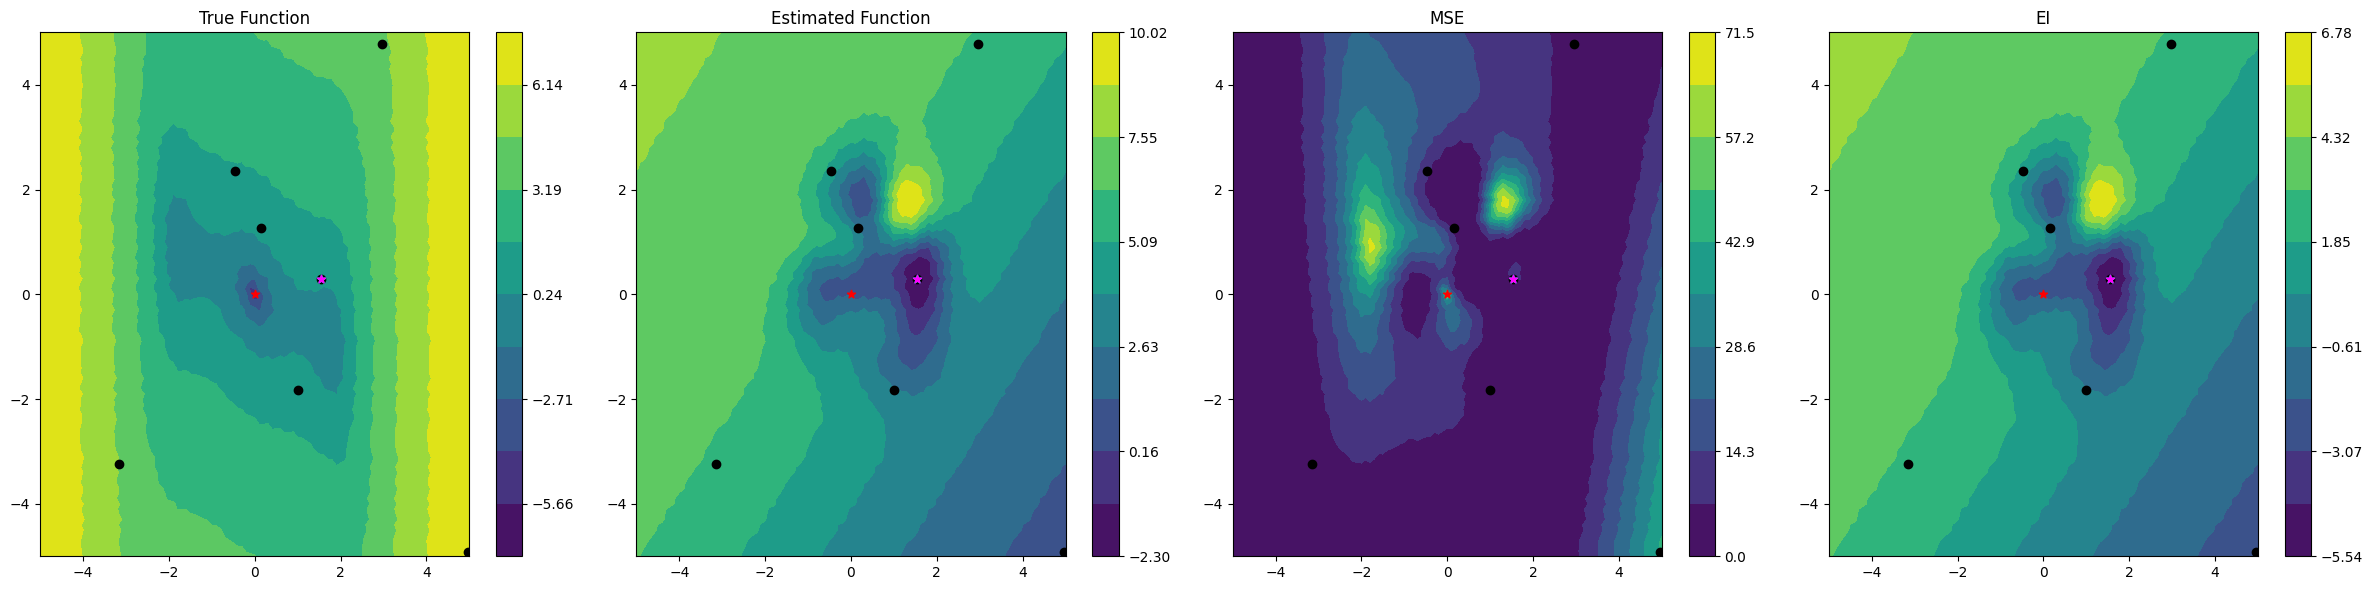

Optimisation error: 1.2826:  30%|███       | 3/10 [00:23<00:55,  7.96s/it]

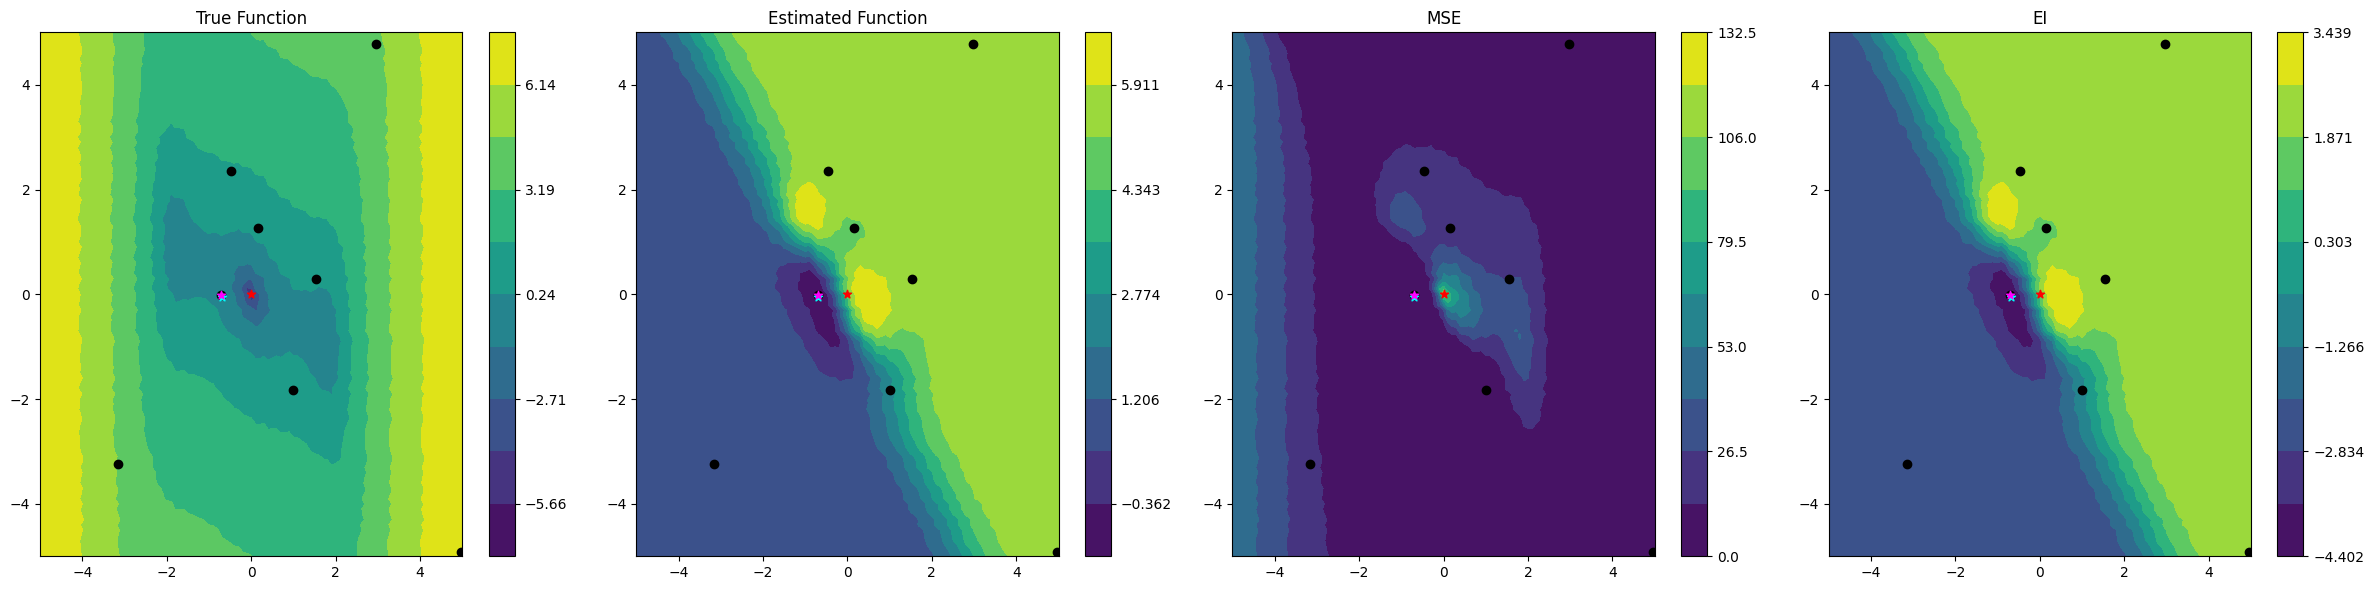

Optimisation error: 0.7073:  40%|████      | 4/10 [00:34<00:55,  9.33s/it]

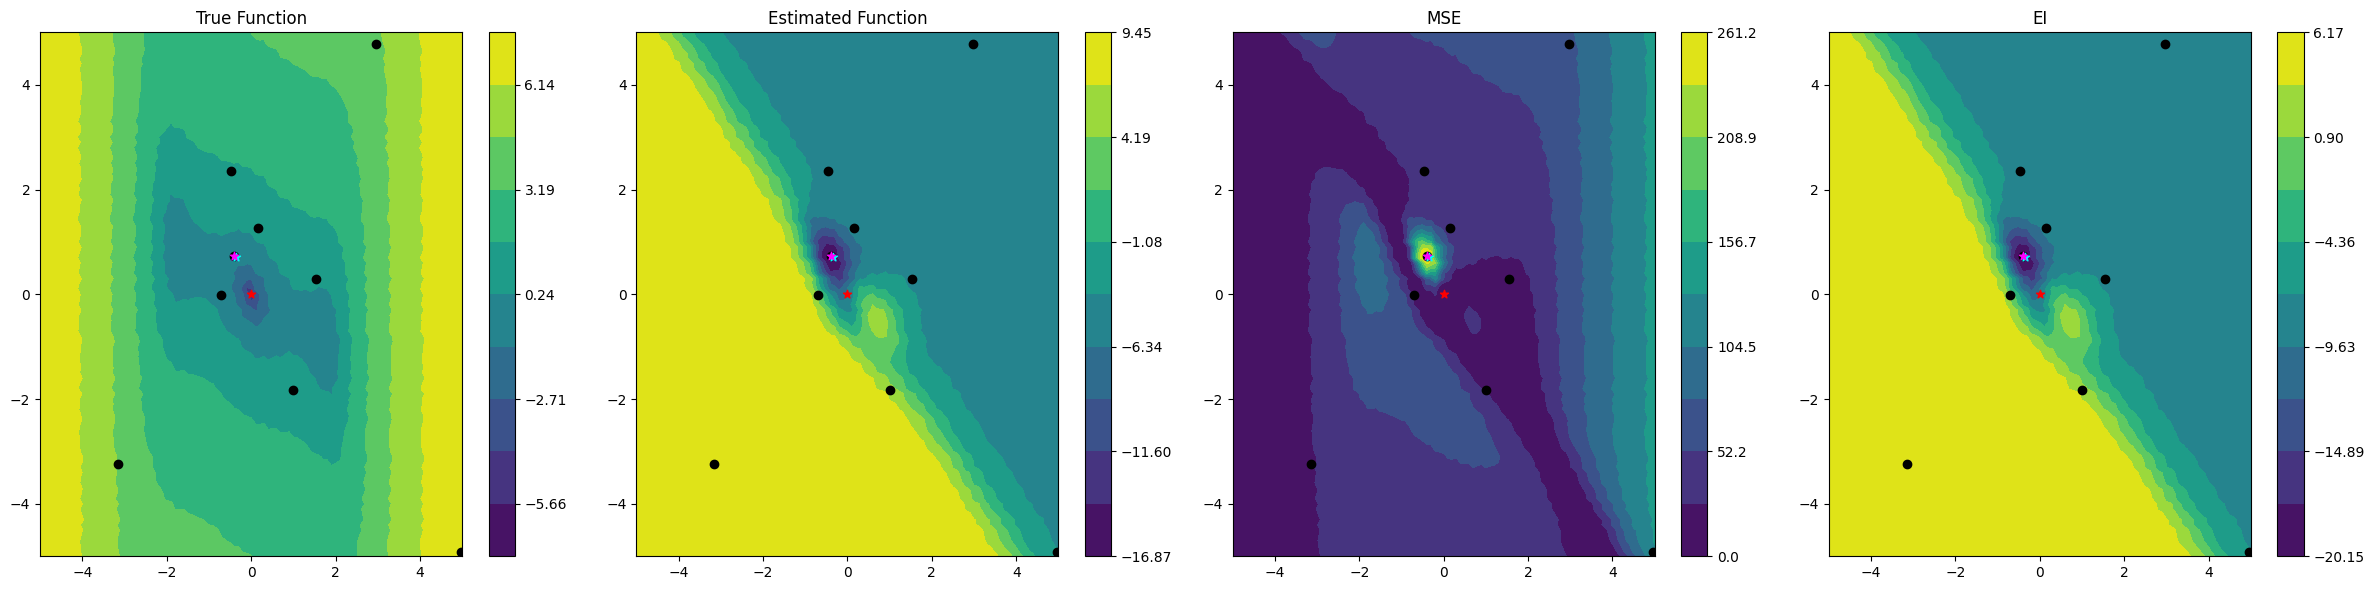

Optimisation error: 0.7073:  50%|█████     | 5/10 [00:44<00:46,  9.39s/it]

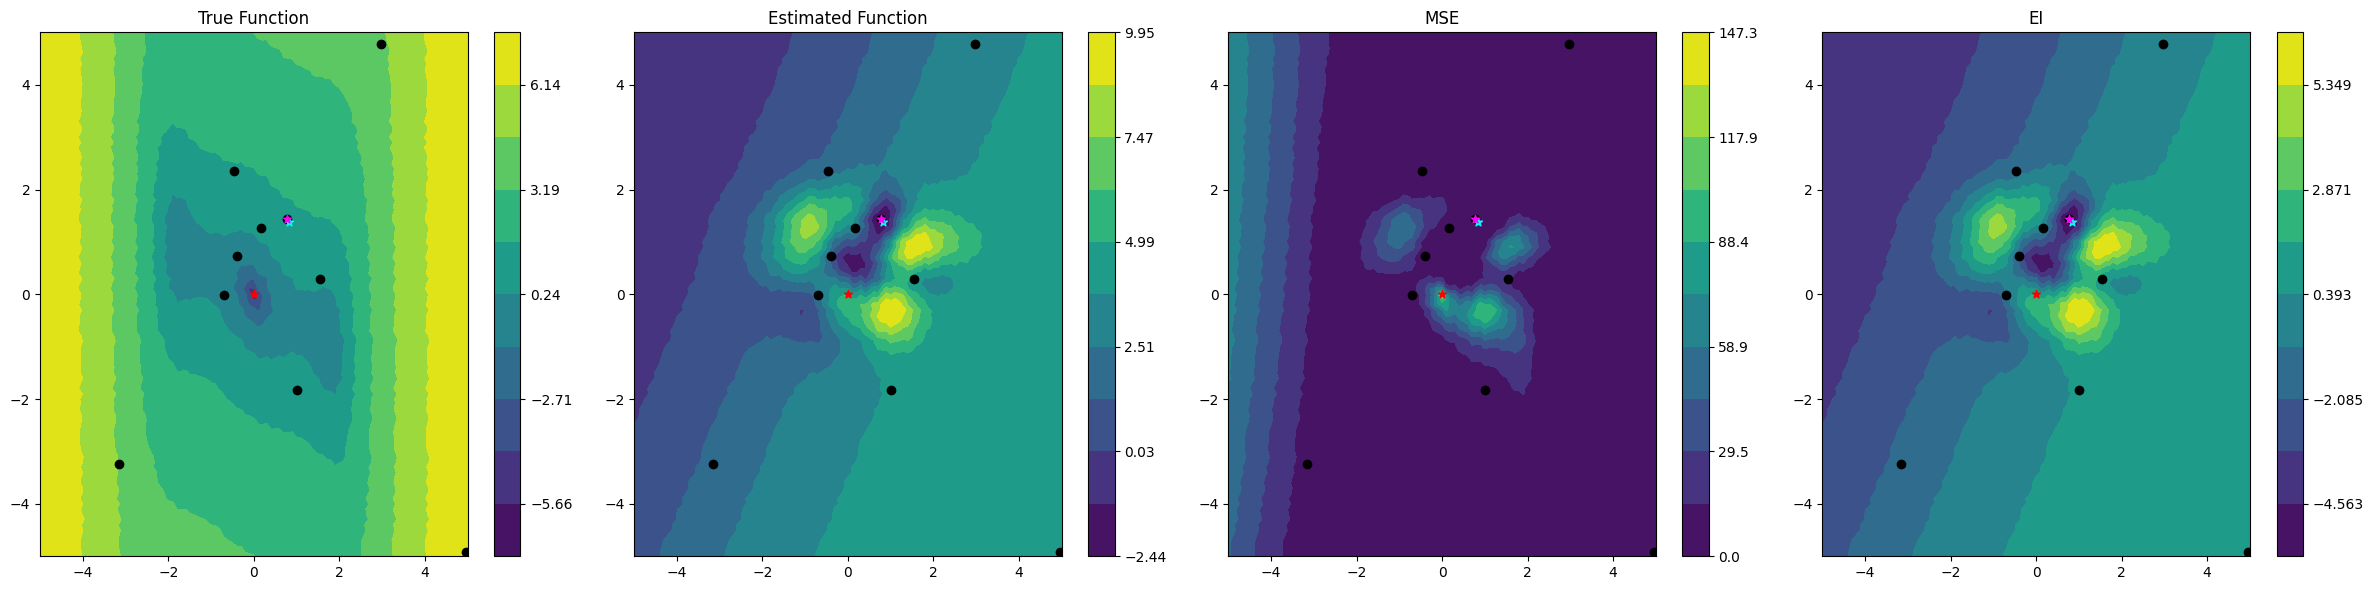

Optimisation error: 0.7073:  60%|██████    | 6/10 [00:50<00:33,  8.38s/it]

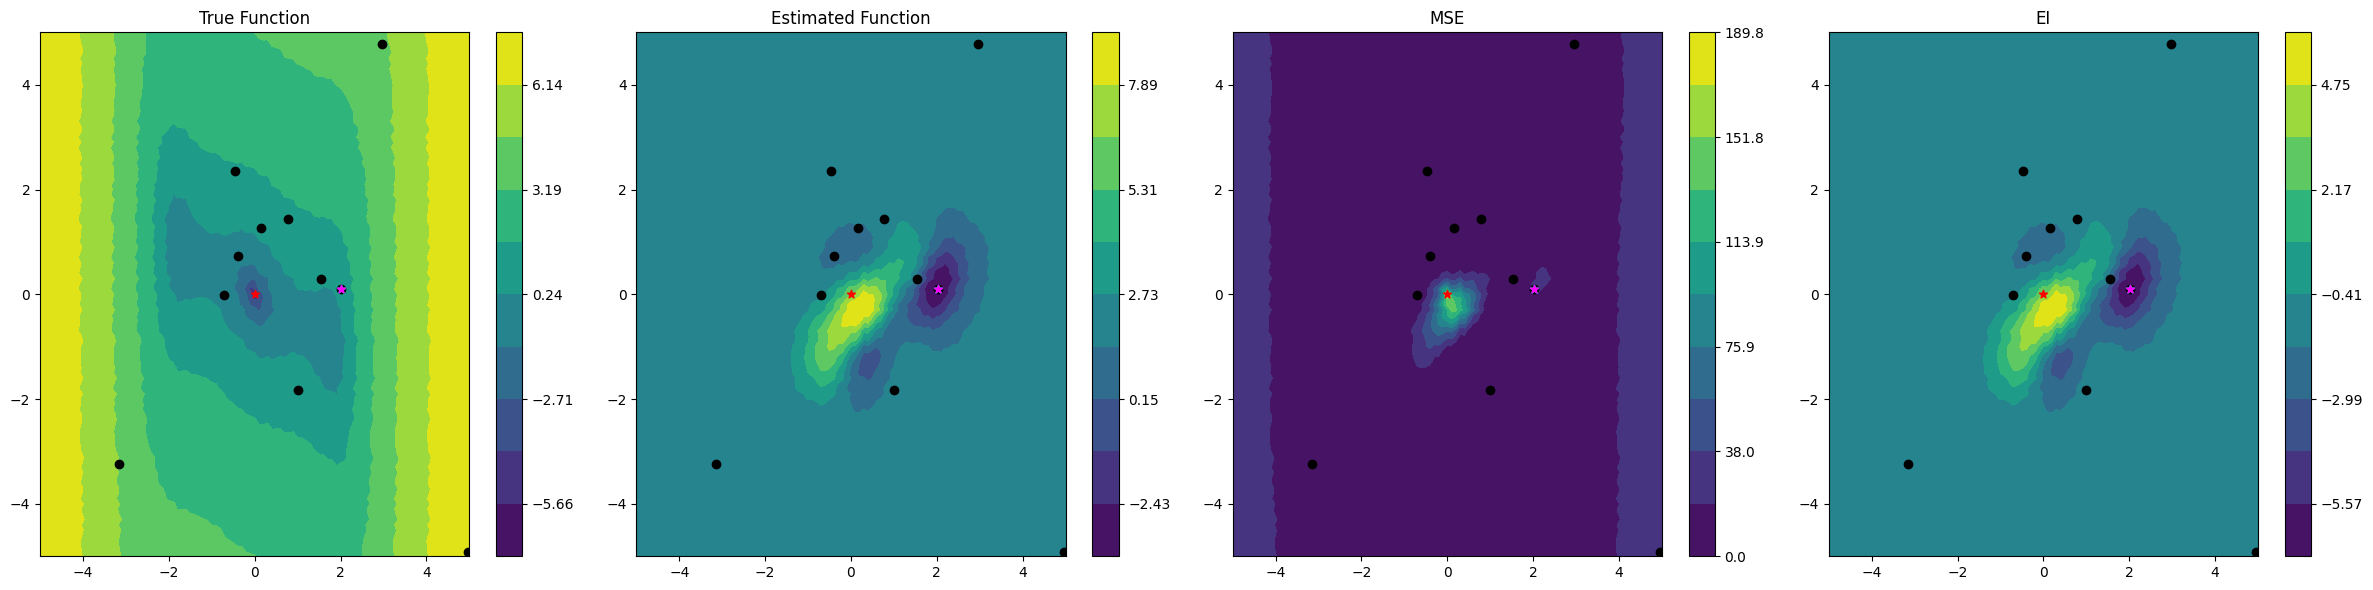

Optimisation error: 0.7073:  70%|███████   | 7/10 [00:59<00:25,  8.38s/it]

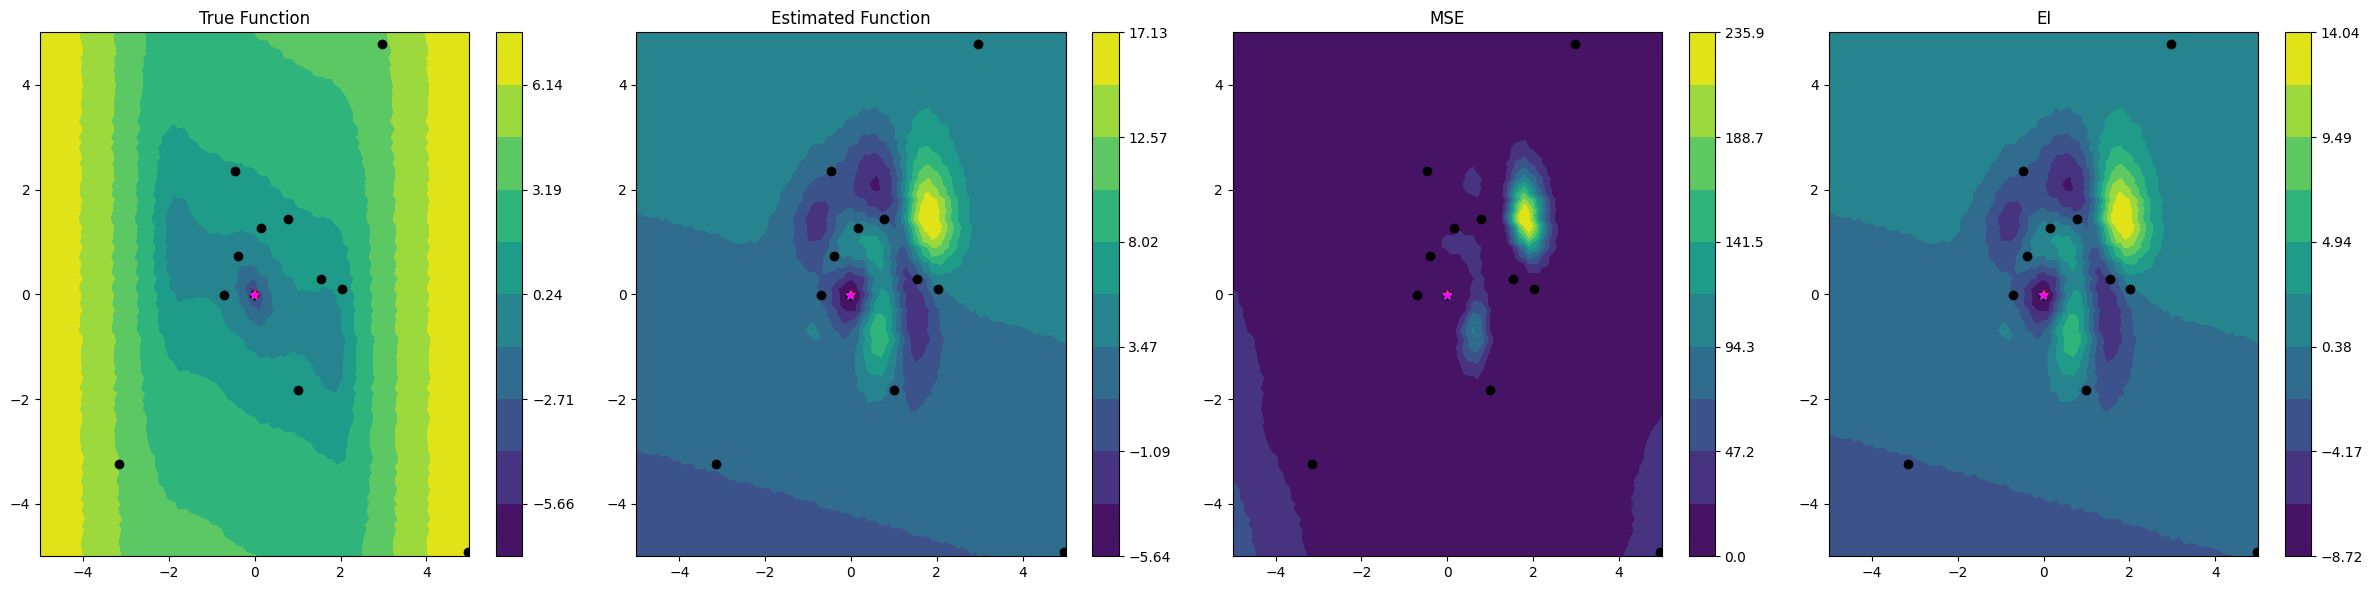

Optimisation error: 0.0200:  80%|████████  | 8/10 [01:12<00:19,  9.94s/it]

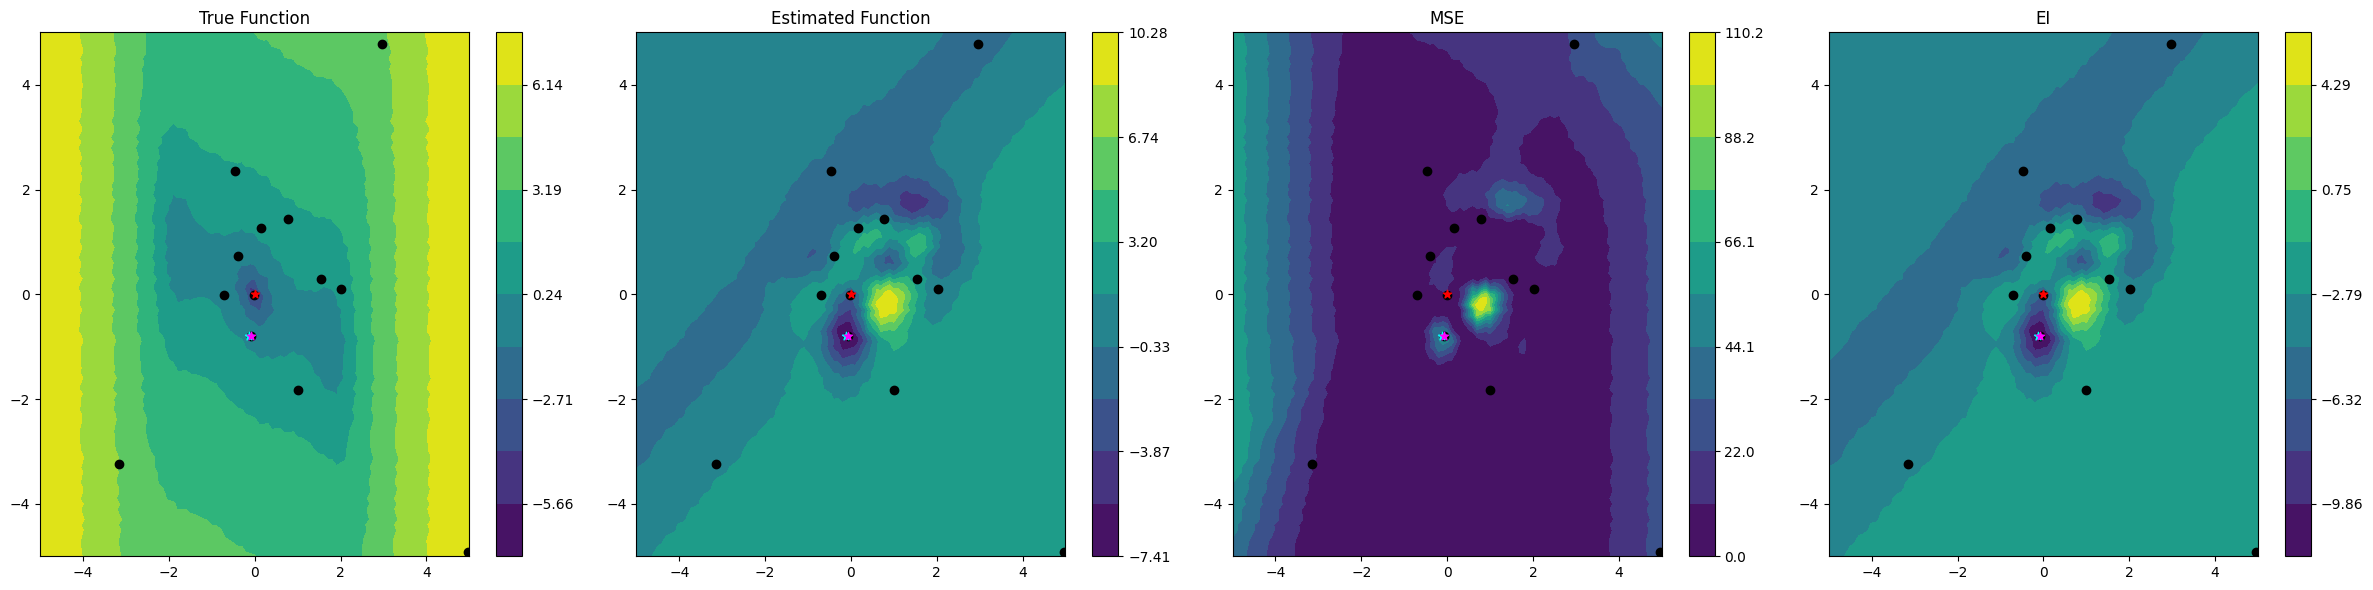

Optimisation error: 0.0200:  90%|█████████ | 9/10 [01:22<00:09,  9.80s/it]

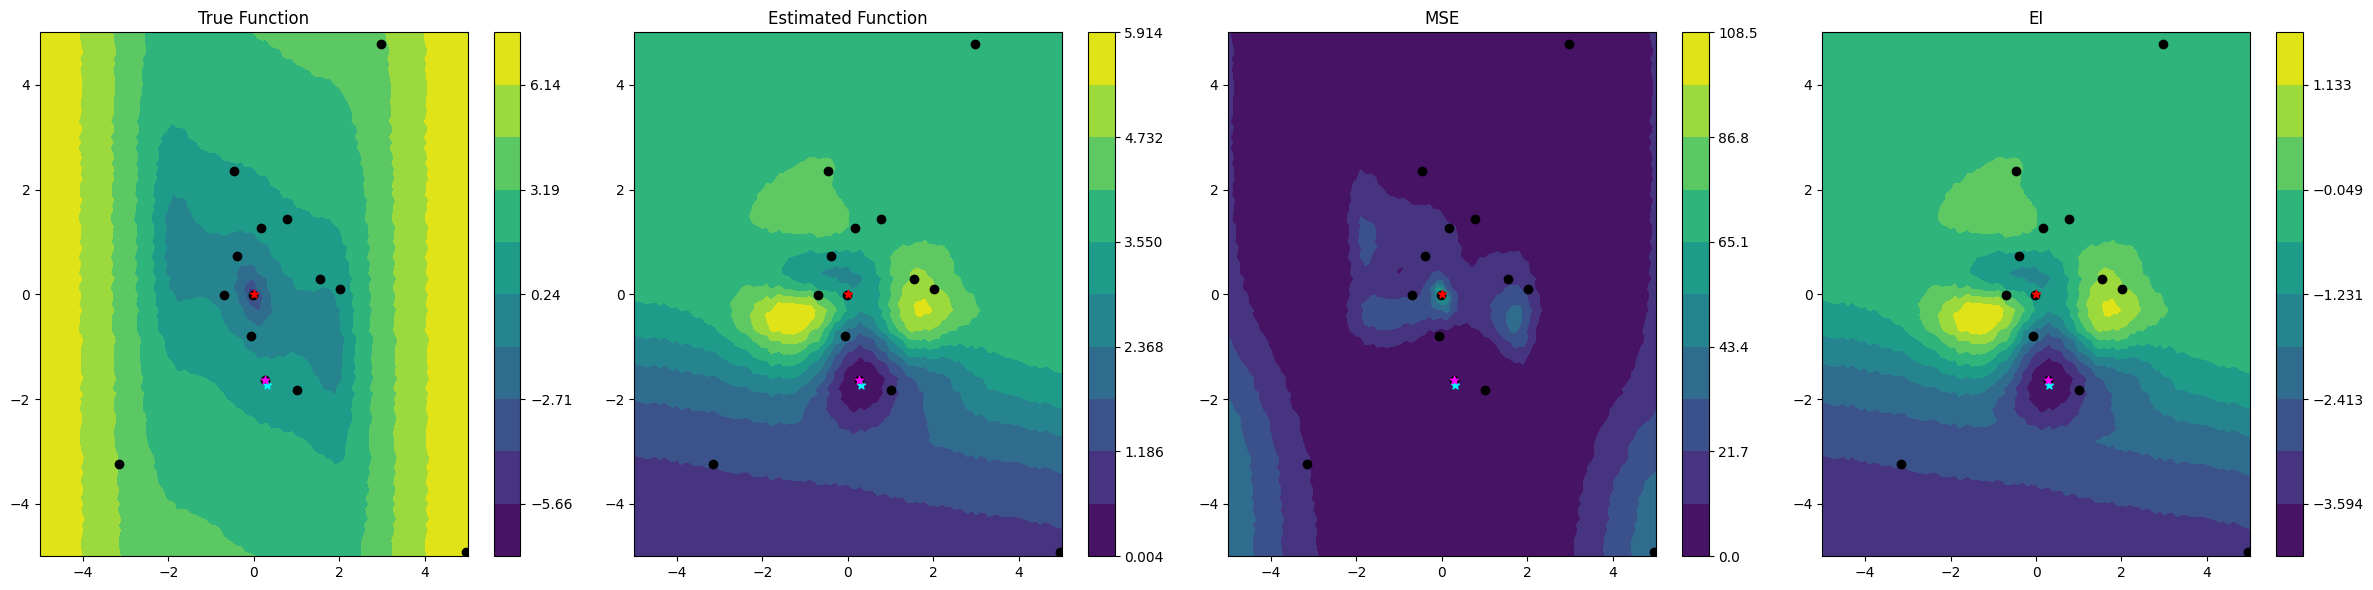

Optimisation error: 0.0200: 100%|██████████| 10/10 [01:31<00:00,  9.10s/it]

Experiment failed


In [4]:
opt = SurrogateOptimiser(
            func=f.three_hump_camel(),
            surr=DGP(n_epochs=10),
            acqf=CB(),
            seed=2,
            max_iter=10,
            plot_results=True,
            verbose=2
)
_ = opt.optimise()

> Результат изменился существенно по сравнению с предыдущим запуском. Этому способствует много факторов, но в первую очередь, конечно же, повлияла смена ф-ии выбора.

>Каждая компонента наследует функционал базового класса. Их можно найти в соответствующих модулях библиотеки, например, ```waggon.functions.base.py```. Реализации компонент достаточно базового класса достаточно для успешного запуска новых модулей.